<a href="https://colab.research.google.com/github/rcoello48/AI-Stock-Market-Prediction/blob/main/Data_Collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance pandas numpy matplotlib seaborn

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
import os

PROJECT_PATH = "/content/drive/MyDrive/AI_Stock_Prediction"

folders = [
    "datasets/raw",
    "datasets/processed",
    "notebooks",
    "models",
    "results",
    "documentation"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [5]:
tickers = [
    "AAPL",
    "MSFT",
    "NVDA",
    "AMZN",
    "TSLA",
    "GOOGL",
    "META",
    "JPM",
    "SPY",
    "QQQ",
    "^VIX"
]

print("Number of financial instruments:", len(tickers))
print("Instruments:", tickers)

Number of financial instruments: 11
Instruments: ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'TSLA', 'GOOGL', 'META', 'JPM', 'SPY', 'QQQ', '^VIX']


In [6]:
# Install yfinance to retrieve historical financial market data
!pip install yfinance

In [7]:
# Download historical daily stock market data from Yahoo Finance

data = yf.download(
    tickers=tickers,          # List of stocks and market indicators
    start="2015-01-01",       # Beginning of historical data
    end="2026-11-01",         # End date (exclusive)
    interval="1d",            # Daily trading frequency
    auto_adjust=True,         # Adjust prices for dividends and stock splits
    group_by="ticker",        # Organise data by financial instrument
    progress=True             # Display download progress
)

# Display confirmation that the download operation has completed
print("Historical market data download completed!")

[*********************100%***********************]  11 of 11 completed

Historical market data download completed!


In [8]:
# Display the dimensions of our downloaded dataset
# The first number represents trading dates (rows)
# The second number represents data columns

print("Dataset dimensions:", data.shape)

# Display the total number of observations
print("Number of trading dates:", data.shape[0])

# Display the total number of columns
print("Number of columns:", data.shape[1])

Dataset dimensions: (2977, 55)
Number of trading dates: 2977
Number of columns: 55


In [9]:
# Display the first five rows of our dataset
# This allows us to inspect the downloaded financial information

display(data.head())

Ticker           TSLA                                                    ^VIX  \
Price            Open       High        Low      Close      Volume       Open   
Date                                                                            
2015-01-02  14.858000  14.883333  14.217333  14.620667  71466000.0  17.760000   
2015-01-05  14.303333  14.433333  13.810667  14.006000  80527500.0  19.190001   
2015-01-06  14.004000  14.280000  13.614000  14.085333  93928500.0  20.330000   
2015-01-07  14.223333  14.318667  13.985333  14.063333  44526000.0  20.150000   
2015-01-08  14.187333  14.253333  14.000667  14.041333  51637500.0  17.930000   

Ticker                                              ...        JPM             \
Price            High        Low      Close Volume  ...       Open       High   
Date                                                ...                         
2015-01-02  20.139999  17.049999  17.790001      0  ...  45.610717  46.182868   
2015-01-05  21.290001  19.190001  19.920000      0  ...  45.522682  45.684056   
2015-01-06  22.900000  19.520000  21.120001      0  ...  44.481083  44.561771   
2015-01-07  20.719999  19.040001  19.309999      0  ...  43.930929  43.930929   
2015-01-08  18.090000  16.990000  17.010000      0  ...  43.989619  44.671799   

Ticker                                             META                        \
Price             Low      Close      Volume       Open       High        Low   
Date                                                                            
2015-01-02  45.530029  45.838112  12600000.0  77.834529  78.181207  76.962872   
2015-01-05  44.180326  44.415054  20100600.0  77.240224  78.498173  76.130847   
2015-01-06  42.801305  43.263428  29074100.0  76.497338  76.853916  74.645075   
2015-01-07  43.036025  43.329437  23843200.0  76.031795  76.626102  75.100711   
2015-01-08  43.989619  44.297699  16971100.0  76.011975  77.487845  75.358240   

Ticker                             
Price           Close      Volume  
Date                               
2015-01-02  77.705757  18177500.0  
2015-01-05  76.457718  26452200.0  
2015-01-06  75.427582  27399300.0  
2015-01-07  75.427582  22045300.0  
2015-01-08  77.438316  23961000.0  

[5 rows x 55 columns]

In [10]:
# Display information about our dataset
# This shows the column names, data types and non-null observations

data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2977 entries, 2015-01-02 to 2026-10-30
Data columns (total 55 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (TSLA, Open)     2975 non-null   float64
 1   (TSLA, High)     2975 non-null   float64
 2   (TSLA, Low)      2975 non-null   float64
 3   (TSLA, Close)    2975 non-null   float64
 4   (TSLA, Volume)   2975 non-null   float64
 5   (^VIX, Open)     2977 non-null   float64
 6   (^VIX, High)     2977 non-null   float64
 7   (^VIX, Low)      2977 non-null   float64
 8   (^VIX, Close)    2977 non-null   float64
 9   (^VIX, Volume)   2977 non-null   int64  
 10  (AAPL, Open)     2975 non-null   float64
 11  (AAPL, High)     2975 non-null   float64
 12  (AAPL, Low)      2975 non-null   float64
 13  (AAPL, Close)    2975 non-null   float64
 14  (AAPL, Volume)   2975 non-null   float64
 15  (QQQ, Open)      2975 non-null   float64
 16  (QQQ, High)      2975 non-null   float64
 

In [11]:
# Count missing values in every column of the dataset
missing_values = data.isnull().sum()

# Display only columns that contain missing values
print("Columns containing missing values:")

display(missing_values[missing_values > 0])

# Calculate the total number of missing values
print("Total missing values:", missing_values.sum())

Columns containing missing values:


Ticker  Price 
TSLA    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
AAPL    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
QQQ     Open      2
        High      2
        Low       2
        Close     2
        Volume    2
GOOGL   Open      2
        High      2
        Low       2
        Close     2
        Volume    2
SPY     Open      2
        High      2
        Low       2
        Close     2
        Volume    2
AMZN    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
NVDA    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
MSFT    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
JPM     Open      2
        High      2
        Low       2
        Close     2
        Volume    2
META    Open      2
        High      2
        Low       2
        Close     2
        Volume    2
dtype: int64

Total missing values: 100


In [12]:
# Identify the dates containing missing observations
# any(axis=1) checks whether at least one column is missing on a given date

missing_dates = data[data.isnull().any(axis=1)]

# Display the dates and corresponding missing observations
print("Dates containing missing values:")

display(missing_dates)

# Display the total number of affected dates
print("Number of affected dates:", len(missing_dates))

Dates containing missing values:


Ticker     TSLA                             ^VIX                               \
Price      Open High Low Close Volume       Open       High        Low  Close   
Date                                                                            
2026-05-25  NaN  NaN NaN   NaN    NaN  16.809999  16.870001  16.530001  16.59   
2026-09-07  NaN  NaN NaN   NaN    NaN  15.020000  15.320000  14.990000  15.30   

Ticker             ...  JPM                       META                        
Price      Volume  ... Open High Low Close Volume Open High Low Close Volume  
Date               ...                                                        
2026-05-25      0  ...  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  
2026-09-07      0  ...  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  

[2 rows x 55 columns]

Number of affected dates: 2


In [13]:
# Remove rows where all financial instruments have missing values
# These dates correspond to US market holidays

data = data.dropna(how="all")

# Display the updated dataset dimensions
print("Dataset dimensions after removing empty dates:", data.shape)

# Verify that no completely empty rows remain
print("Completely empty rows:", data.isnull().all(axis=1).sum())

Dataset dimensions after removing empty dates: (2977, 55)
Completely empty rows: 0


In [14]:
# Exclude VIX because it has observations on the dates
# when the regular US stock market was closed

stock_data = data.loc[
    :,
    data.columns.get_level_values(0) != "^VIX"
]

# Identify dates where all stock and ETF observations are missing
market_closed_dates = stock_data.isna().all(axis=1)

# Display the dates identified as market closures
print("Potential US market closure dates:")

display(data.loc[market_closed_dates])

# Count the identified dates
print("Number of identified dates:", market_closed_dates.sum())

Potential US market closure dates:


Ticker     TSLA                             ^VIX                               \
Price      Open High Low Close Volume       Open       High        Low  Close   
Date                                                                            
2026-05-25  NaN  NaN NaN   NaN    NaN  16.809999  16.870001  16.530001  16.59   
2026-09-07  NaN  NaN NaN   NaN    NaN  15.020000  15.320000  14.990000  15.30   

Ticker             ...  JPM                       META                        
Price      Volume  ... Open High Low Close Volume Open High Low Close Volume  
Date               ...                                                        
2026-05-25      0  ...  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  
2026-09-07      0  ...  NaN  NaN NaN   NaN    NaN  NaN  NaN NaN   NaN    NaN  

[2 rows x 55 columns]

Number of identified dates: 2


In [15]:
# Remove dates when all stock and ETF markets were closed
# Keep all valid trading observations

data = data.loc[~market_closed_dates].copy()

# Display the updated dataset dimensions
print("Updated dataset dimensions:", data.shape)

# Verify that the identified market closure dates were removed
print("Remaining market closure dates:",
      data.loc[market_closed_dates.reindex(data.index, fill_value=False)].shape[0]
)

Updated dataset dimensions: (2975, 55)
Remaining market closure dates: 0


In [16]:
# Count missing values across all columns
remaining_missing = data.isnull().sum()

# Display columns that still contain missing values
print("Remaining missing values by column:")

display(remaining_missing[remaining_missing > 0])

# Calculate the total number of missing values
print("Total remaining missing values:", remaining_missing.sum())

Remaining missing values by column:


,,0
Ticker,Price,


Total remaining missing values: 0


In [17]:
# Define the destination path for our processed dataset
processed_path = f"{PROJECT_PATH}/datasets/processed/cleaned_stock_market_data.csv"

# Save the cleaned financial dataset as a CSV file
# index=True preserves the trading dates
# header=True preserves our ticker and price column levels
data.to_csv(processed_path, index=True, header=True)

# Display a confirmation message
print("Cleaned dataset saved successfully!")

# Display the location of the saved dataset
print("Saved file:", processed_path)

Cleaned dataset saved successfully!
Saved file: /content/drive/MyDrive/AI_Stock_Prediction/datasets/processed/cleaned_stock_market_data.csv


In [18]:
# Load the cleaned financial dataset from Google Drive
# This allows us to reuse the saved dataset without downloading it again

cleaned_data = pd.read_csv(
    processed_path,
    header=[0, 1],       # Read both levels of our MultiIndex columns
    index_col=0,         # Use the Date column as the DataFrame index
    parse_dates=True     # Convert the index into datetime format
)

# Display the dataset dimensions
print("Dataset dimensions:", cleaned_data.shape)

# Display the first five observations
display(cleaned_data.head())

Dataset dimensions: (2975, 55)


Ticker           TSLA                                                    ^VIX  \
Price            Open       High        Low      Close      Volume       Open   
Date                                                                            
2015-01-02  14.858000  14.883333  14.217333  14.620667  71466000.0  17.760000   
2015-01-05  14.303333  14.433333  13.810667  14.006000  80527500.0  19.190001   
2015-01-06  14.004000  14.280000  13.614000  14.085333  93928500.0  20.330000   
2015-01-07  14.223333  14.318667  13.985333  14.063333  44526000.0  20.150000   
2015-01-08  14.187333  14.253333  14.000667  14.041333  51637500.0  17.930000   

Ticker                                              ...        JPM             \
Price            High        Low      Close Volume  ...       Open       High   
Date                                                ...                         
2015-01-02  20.139999  17.049999  17.790001      0  ...  45.610717  46.182868   
2015-01-05  21.290001  19.190001  19.920000      0  ...  45.522682  45.684056   
2015-01-06  22.900000  19.520000  21.120001      0  ...  44.481083  44.561771   
2015-01-07  20.719999  19.040001  19.309999      0  ...  43.930929  43.930929   
2015-01-08  18.090000  16.990000  17.010000      0  ...  43.989619  44.671799   

Ticker                                             META                        \
Price             Low      Close      Volume       Open       High        Low   
Date                                                                            
2015-01-02  45.530029  45.838112  12600000.0  77.834529  78.181207  76.962872   
2015-01-05  44.180326  44.415054  20100600.0  77.240224  78.498173  76.130847   
2015-01-06  42.801305  43.263428  29074100.0  76.497338  76.853916  74.645075   
2015-01-07  43.036025  43.329437  23843200.0  76.031795  76.626102  75.100711   
2015-01-08  43.989619  44.297699  16971100.0  76.011975  77.487845  75.358240   

Ticker                             
Price           Close      Volume  
Date                               
2015-01-02  77.705757  18177500.0  
2015-01-05  76.457718  26452200.0  
2015-01-06  75.427582  27399300.0  
2015-01-07  75.427582  22045300.0  
2015-01-08  77.438316  23961000.0  

[5 rows x 55 columns]

In [19]:
# Check that the dataset dates were loaded as datetime values
print("Date index type:", type(cleaned_data.index))

# Display all available ticker symbols
print("\nAvailable tickers:")
print(cleaned_data.columns.get_level_values(0).unique().tolist())

# Display all available price fields
print("\nAvailable price fields:")
print(cleaned_data.columns.get_level_values(1).unique().tolist())

# Confirm the date range covered by our dataset
print("\nDataset start date:", cleaned_data.index.min())
print("Dataset end date:", cleaned_data.index.max())

Date index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

Available tickers:
['TSLA', '^VIX', 'AAPL', 'QQQ', 'GOOGL', 'SPY', 'AMZN', 'NVDA', 'MSFT', 'JPM', 'META']

Available price fields:
['Open', 'High', 'Low', 'Close', 'Volume']

Dataset start date: 2015-01-02 00:00:00
Dataset end date: 2026-10-30 00:00:00


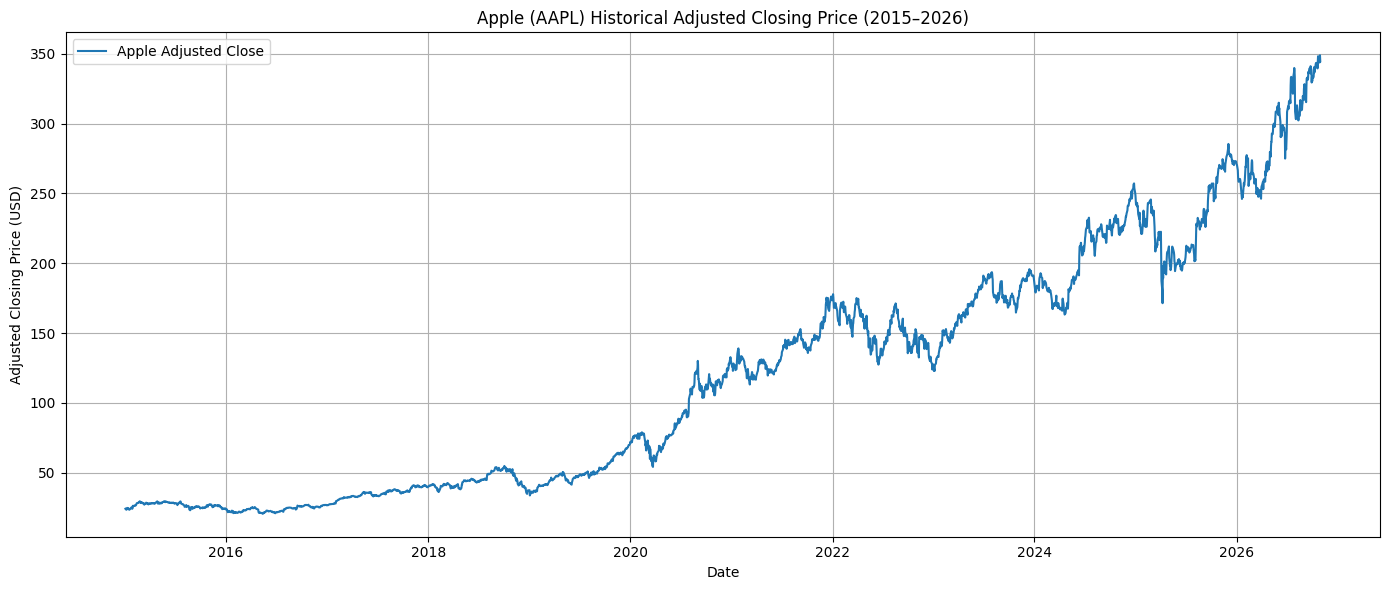

In [20]:
# Create a figure for Apple's historical adjusted closing price
plt.figure(figsize=(14, 6))

# Extract Apple's adjusted closing prices and plot them over time
plt.plot(
    cleaned_data.index,
    cleaned_data[("AAPL", "Close")],
    label="Apple Adjusted Close"
)

# Add a descriptive title and axis labels
plt.title("Apple (AAPL) Historical Adjusted Closing Price (2015–2026)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")

# Display a grid and legend to make the chart easier to read
plt.grid(True)
plt.legend()

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

Apple Daily Returns Summary:


,AAPL
,Close
count,2974.000000
mean,0.001056
std,0.018037
min,-0.128647
25%,-0.007329
50%,0.001001
75%,0.010016
max,0.153289


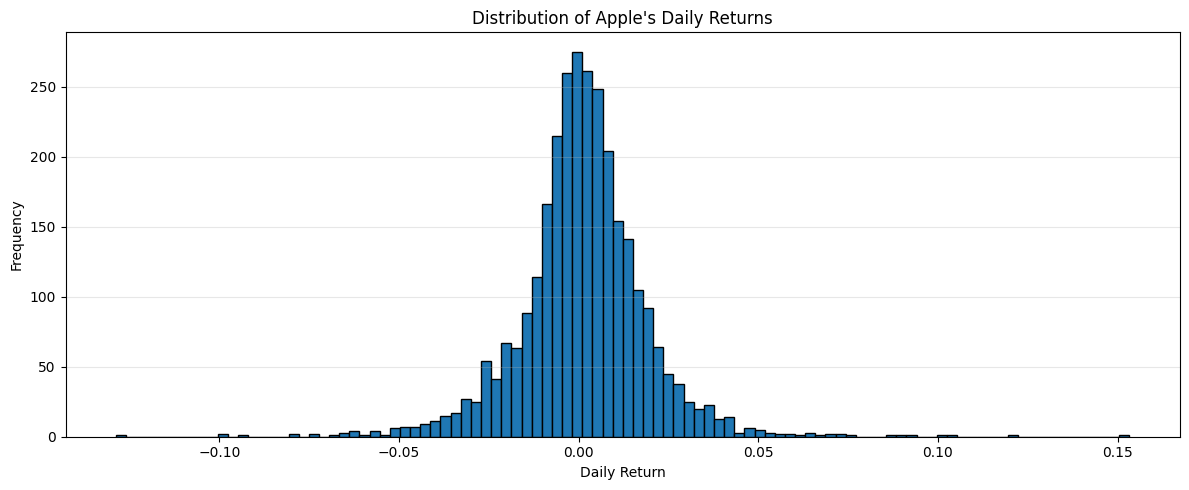

In [21]:
# Calculate Apple's daily percentage returns
# pct_change() measures the percentage change from the previous trading day
aapl_returns = cleaned_data[("AAPL", "Close")].pct_change()

# Remove the first missing value because it has no previous trading day
aapl_returns = aapl_returns.dropna()

# Display basic statistics about Apple's daily returns
print("Apple Daily Returns Summary:")
display(aapl_returns.describe())

# Plot the distribution of daily returns
plt.figure(figsize=(12, 5))

plt.hist(
    aapl_returns,
    bins=100,
    edgecolor="black"
)

# Add chart labels and title
plt.title("Distribution of Apple's Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")

# Display the chart
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


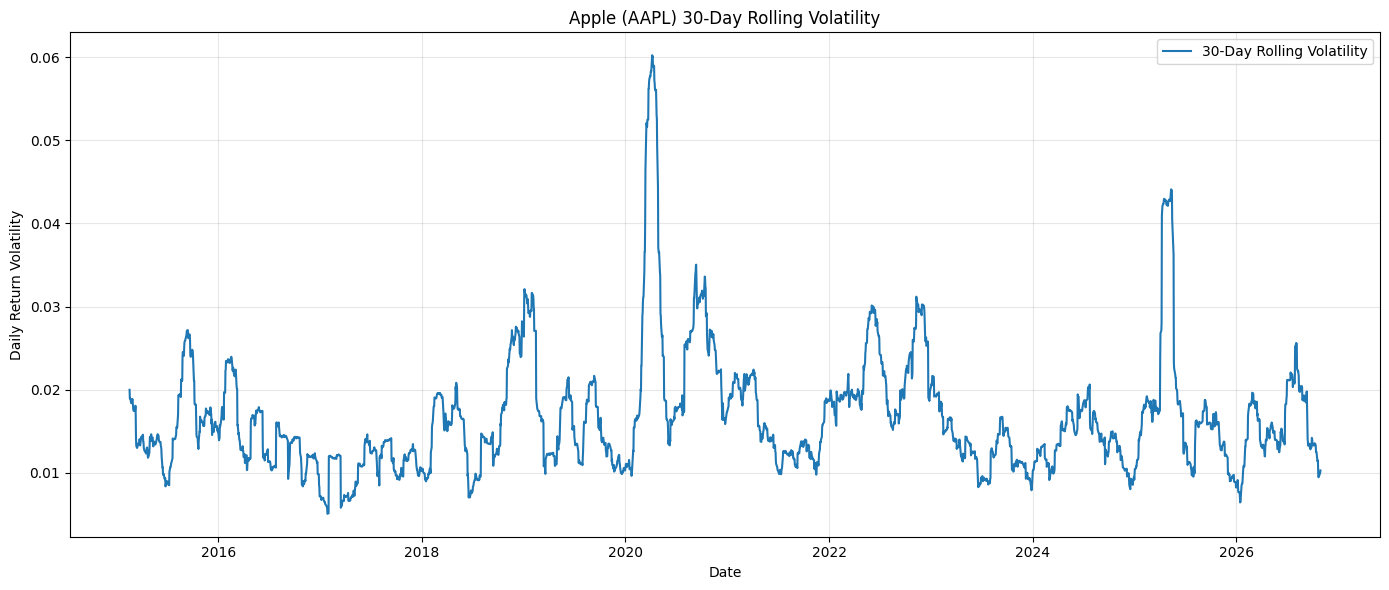

Average 30-day rolling volatility: 1.6579 %


In [22]:
# Calculate rolling 30-day volatility using Apple's daily returns
# A 30-day window represents the previous 30 trading observations
aapl_volatility = aapl_returns.rolling(window=30).std()

# Create a figure for the rolling volatility chart
plt.figure(figsize=(14, 6))

# Plot the rolling volatility over time
plt.plot(
    aapl_volatility.index,
    aapl_volatility,
    label="30-Day Rolling Volatility"
)

# Add chart title and axis labels
plt.title("Apple (AAPL) 30-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Daily Return Volatility")

# Add a legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Display the chart
plt.tight_layout()
plt.show()

# Display the average 30-day rolling volatility
print(
    "Average 30-day rolling volatility:",
    round(aapl_volatility.mean() * 100, 4),
    "%"
)

In [23]:
# Display the average rolling volatility as a percentage
print(
    "Average 30-day rolling volatility:",
    round(aapl_volatility.mean() * 100, 4),
    "%"
)

Average 30-day rolling volatility: 1.6579 %


,Average Daily Return (%),Daily Volatility (%),Minimum Daily Return (%),Maximum Daily Return (%)
Ticker,,,,
TSLA,0.175,3.588,-21.063,22.690
AAPL,0.106,1.804,-12.865,15.329
QQQ,0.076,1.380,-11.979,12.003
GOOGL,0.097,1.843,-12.641,16.258
SPY,0.056,1.102,-10.942,10.502
AMZN,0.114,2.083,-14.049,15.321
NVDA,0.249,3.024,-18.756,29.807
MSFT,0.102,1.734,-14.739,15.507
JPM,0.081,1.689,-14.965,18.012


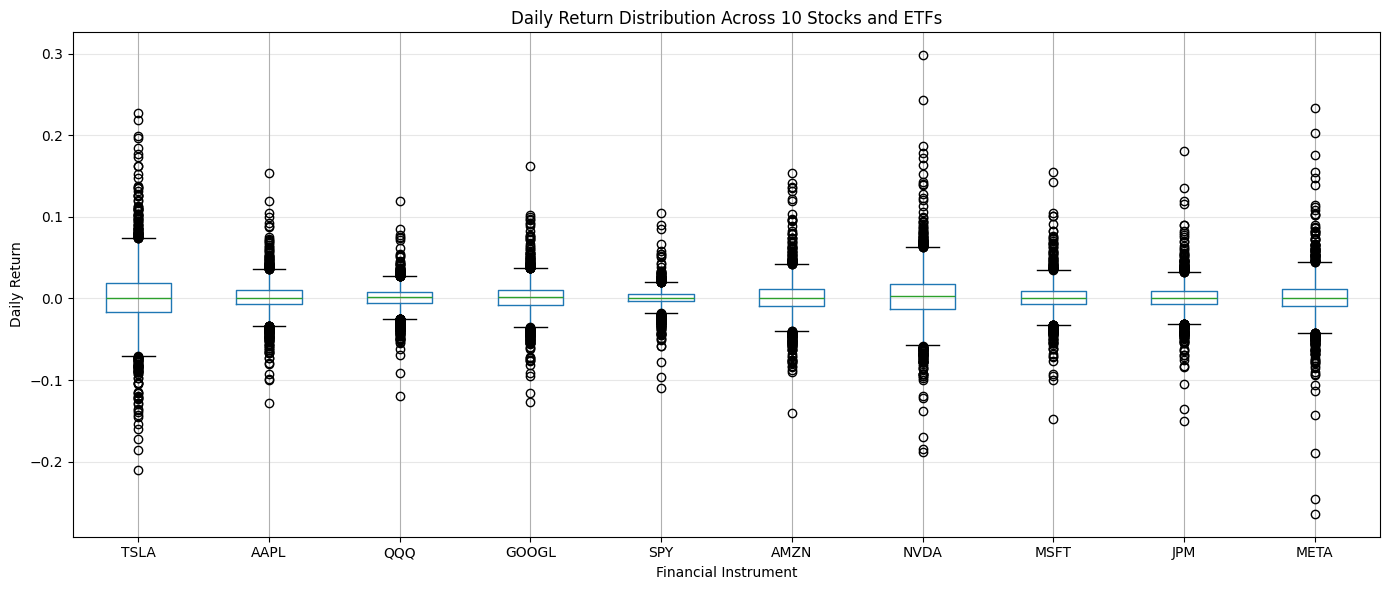

In [24]:
# Extract the adjusted closing prices for all financial instruments
close_prices = cleaned_data.xs("Close", axis=1, level=1)

# Exclude VIX because it is a volatility index, not a stock or ETF
equity_prices = close_prices.drop(columns=["^VIX"])

# Calculate daily percentage returns for all 10 stocks and ETFs
asset_returns = equity_prices.pct_change().dropna()

# Calculate summary statistics for each asset
# Standard deviation measures the historical variability of daily returns
return_summary = pd.DataFrame({
    "Average Daily Return (%)": asset_returns.mean() * 100,
    "Daily Volatility (%)": asset_returns.std() * 100,
    "Minimum Daily Return (%)": asset_returns.min() * 100,
    "Maximum Daily Return (%)": asset_returns.max() * 100
})

# Display the comparison table
display(return_summary.round(3))

# Create a boxplot to compare the distribution of daily returns
plt.figure(figsize=(14, 6))

asset_returns.boxplot()

# Add chart labels and title
plt.title("Daily Return Distribution Across 10 Stocks and ETFs")
plt.xlabel("Financial Instrument")
plt.ylabel("Daily Return")

# Display the chart
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Ticker,TSLA,AAPL,QQQ,GOOGL,SPY,AMZN,NVDA,MSFT,JPM,META
Ticker,,,,,,,,,,
TSLA,1.00,0.42,0.56,0.38,0.50,0.40,0.41,0.39,0.28,0.34
AAPL,0.42,1.00,0.76,0.55,0.73,0.52,0.50,0.62,0.41,0.49
QQQ,0.56,0.76,1.00,0.75,0.93,0.73,0.73,0.80,0.53,0.68
GOOGL,0.38,0.55,0.75,1.00,0.69,0.63,0.50,0.63,0.38,0.58
SPY,0.50,0.73,0.93,0.69,1.00,0.63,0.65,0.75,0.71,0.60
AMZN,0.40,0.52,0.73,0.63,0.63,1.00,0.50,0.63,0.30,0.58
NVDA,0.41,0.50,0.73,0.50,0.65,0.50,1.00,0.57,0.33,0.47
MSFT,0.39,0.62,0.80,0.63,0.75,0.63,0.57,1.00,0.41,0.54
JPM,0.28,0.41,0.53,0.38,0.71,0.30,0.33,0.41,1.00,0.32


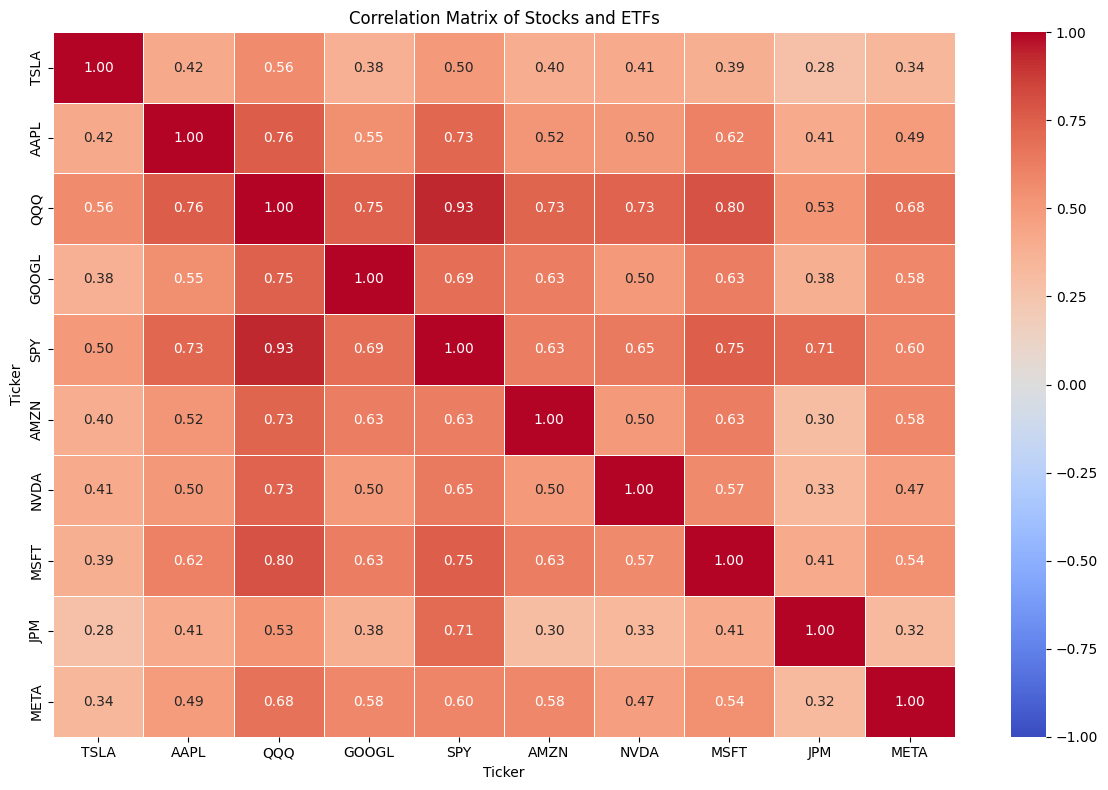

In [25]:
# Calculate the correlation matrix using daily returns
# Correlation helps identify assets that move together
correlation_matrix = asset_returns.corr()

# Display the numerical correlation matrix
display(correlation_matrix.round(2))

# Create a heatmap to visualise relationships between assets
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,          # Display correlation values inside each cell
    cmap="coolwarm",     # Use colours to distinguish positive and negative relationships
    fmt=".2f",           # Display values to two decimal places
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

# Add a title
plt.title("Correlation Matrix of Stocks and ETFs")

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

Correlation Between Asset Returns and Daily VIX Changes:


,VIX Change
SPY,-0.730
QQQ,-0.697
MSFT,-0.544
GOOGL,-0.519
AAPL,-0.518
JPM,-0.514
NVDA,-0.498
AMZN,-0.485
META,-0.435
TSLA,-0.376


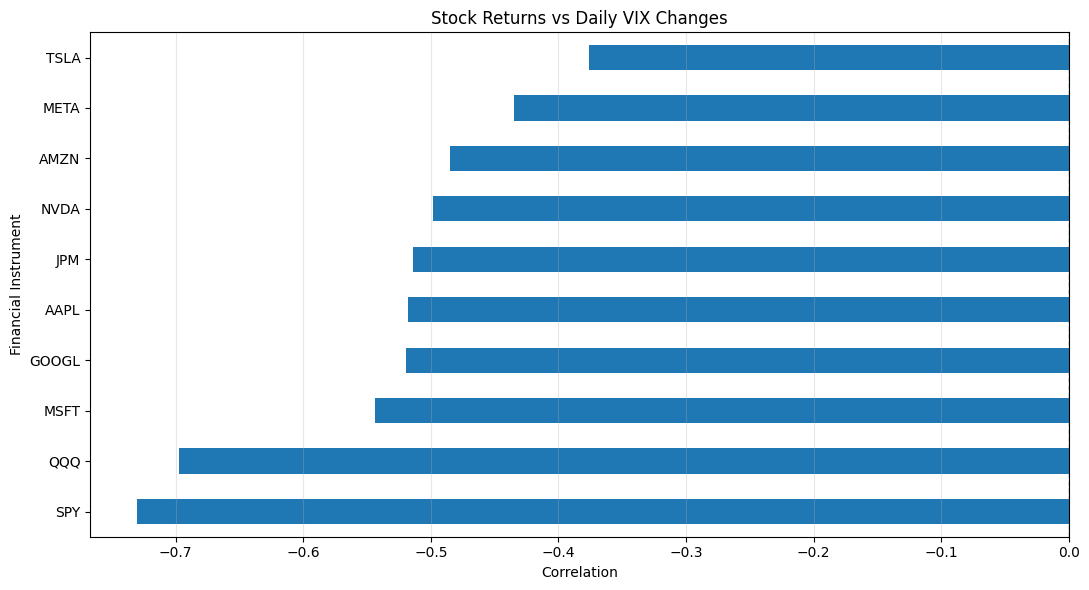

In [26]:
# Extract the VIX adjusted closing price
vix_prices = cleaned_data[("^VIX", "Close")]

# Calculate daily percentage changes in VIX
# This measures how much the VIX rises or falls each trading day
vix_returns = vix_prices.pct_change()

# Combine stock returns and VIX changes into one DataFrame
# Aligning by date ensures that observations correspond to the same trading day
vix_comparison = asset_returns.join(
    vix_returns.rename("VIX Change")
).dropna()

# Calculate the correlation between each asset's return and VIX changes
vix_correlation = (
    vix_comparison.corr()["VIX Change"]
    .drop("VIX Change")
    .sort_values()
)

# Display the correlations
print("Correlation Between Asset Returns and Daily VIX Changes:")
display(vix_correlation.round(3))

# Visualise the relationships using a horizontal bar chart
plt.figure(figsize=(11, 6))

vix_correlation.plot(kind="barh")

# Add chart labels and title
plt.title("Stock Returns vs Daily VIX Changes")
plt.xlabel("Correlation")
plt.ylabel("Financial Instrument")

# Add a reference line at zero correlation
plt.axvline(x=0, linestyle="--", linewidth=1)

# Display the chart
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Create an empty DataFrame to store machine-learning features
# Each row represents one trading date
features = pd.DataFrame(index=cleaned_data.index)

# Identify the 10 stocks and ETFs
# VIX will be handled separately as a market indicator
asset_tickers = equity_prices.columns.tolist()

# Generate technical indicators for every stock and ETF
for ticker in asset_tickers:

    # Extract the adjusted closing price for the current asset
    price = cleaned_data[(ticker, "Close")]

    # Calculate daily percentage return
    features[f"{ticker}_return_1d"] = price.pct_change()

    # Calculate returns over the previous 5 trading days
    features[f"{ticker}_return_5d"] = price.pct_change(periods=5)

    # Calculate returns over the previous 20 trading days
    features[f"{ticker}_return_20d"] = price.pct_change(periods=20)

    # Calculate the 5-day moving average relative to the current price
    features[f"{ticker}_sma_5_ratio"] = (
        price / price.rolling(window=5).mean() - 1
    )

    # Calculate the 20-day moving average relative to the current price
    features[f"{ticker}_sma_20_ratio"] = (
        price / price.rolling(window=20).mean() - 1
    )

    # Calculate 20-day rolling volatility using daily returns
    features[f"{ticker}_volatility_20d"] = (
        price.pct_change().rolling(window=20).std()
    )

# Add VIX market information as additional model features
vix_price = cleaned_data[("^VIX", "Close")]

# Current VIX level
features["VIX_level"] = vix_price

# Daily percentage change in VIX
features["VIX_change_1d"] = vix_price.pct_change()

# Five-day percentage change in VIX
features["VIX_change_5d"] = vix_price.pct_change(periods=5)

# Display the dimensions of the newly created feature dataset
print("Feature dataset dimensions:", features.shape)

# Display the first five rows
display(features.head())

Feature dataset dimensions: (2975, 63)


,TSLA_return_1d,TSLA_return_5d,TSLA_return_20d,TSLA_sma_5_ratio,TSLA_sma_20_ratio,TSLA_volatility_20d,AAPL_return_1d,AAPL_return_5d,AAPL_return_20d,AAPL_sma_5_ratio,...,JPM_volatility_20d,META_return_1d,META_return_5d,META_return_20d,META_sma_5_ratio,META_sma_20_ratio,META_volatility_20d,VIX_level,VIX_change_1d,VIX_change_5d
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.790001,NaN,NaN
2015-01-05,-0.042041,NaN,NaN,NaN,NaN,NaN,-0.028171,NaN,NaN,NaN,...,NaN,-0.016061,NaN,NaN,NaN,NaN,NaN,19.920000,0.119730,NaN
2015-01-06,0.005664,NaN,NaN,NaN,NaN,NaN,0.000094,NaN,NaN,NaN,...,NaN,-0.013473,NaN,NaN,NaN,NaN,NaN,21.120001,0.060241,NaN
2015-01-07,-0.001562,NaN,NaN,NaN,NaN,NaN,0.014022,NaN,NaN,NaN,...,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,19.309999,-0.085701,NaN
2015-01-08,-0.001564,NaN,NaN,-0.008614,NaN,NaN,0.038422,NaN,NaN,0.033187,...,NaN,0.026658,NaN,NaN,0.01238,NaN,NaN,17.010000,-0.119109,NaN


In [28]:
# Count missing values in every engineered feature
missing_features = features.isnull().sum()

# Display only features containing missing values
display(
    missing_features[missing_features > 0]
    .sort_values(ascending=False)
)

# Calculate the total number of missing feature values
print("\nTotal missing feature values:", features.isnull().sum().sum())

# Identify how many dates contain at least one missing feature
print(
    "Rows containing missing values:",
    features.isnull().any(axis=1).sum()
)

# Identify the first date where all features are available
print(
    "First complete feature date:",
    features.dropna().index.min()
)

,0
TSLA_volatility_20d,20
TSLA_return_20d,20
AAPL_volatility_20d,20
AAPL_return_20d,20
QQQ_volatility_20d,20
...,...
NVDA_return_1d,1
MSFT_return_1d,1
JPM_return_1d,1
META_return_1d,1



Total missing feature values: 696
Rows containing missing values: 20
First complete feature date: 2015-02-02 00:00:00


In [29]:
# Remove rows containing missing feature values
# The first 20 observations are incomplete because of rolling calculations
features_clean = features.dropna().copy()

# Display the dimensions after cleaning
print("Original feature dimensions:", features.shape)
print("Cleaned feature dimensions:", features_clean.shape)

# Verify that no missing values remain
print(
    "\nRemaining missing values:",
    features_clean.isnull().sum().sum()
)

# Display the first available date
print("First available date:", features_clean.index.min())

# Display the final available date
print("Last available date:", features_clean.index.max())

Original feature dimensions: (2975, 63)
Cleaned feature dimensions: (2955, 63)

Remaining missing values: 0
First available date: 2015-02-02 00:00:00
Last available date: 2026-10-30 00:00:00


In [30]:
# Create an empty DataFrame to store our prediction targets
targets = pd.DataFrame(index=features_clean.index)

# Loop through all 10 stocks and ETFs
for ticker in asset_tickers:

    # Extract the current adjusted closing price
    current_price = close_prices[ticker]

    # Shift prices by one trading day to obtain the NEXT trading day's price
    next_price = current_price.shift(-1)

    # Classification target:
    # 1 means the next day's price is higher than today's price
    # 0 means the next day's price is equal to or lower than today's price
    targets[f"{ticker}_direction"] = (
        next_price > current_price
    ).astype(int)

    # Regression target:
    # Predict the next trading day's adjusted closing price
    targets[f"{ticker}_next_close"] = next_price

# Remove the final observation because its next trading day's price is unknown
# This prevents us from creating an invalid prediction target
targets = targets.iloc[:-1].copy()

# Align the feature dataset with the target dataset
features_final = features_clean.loc[targets.index].copy()

# Display the dimensions of both datasets
print("Final feature dimensions:", features_final.shape)
print("Prediction target dimensions:", targets.shape)

# Display the first five prediction target observations
display(targets.head())

Final feature dimensions: (2954, 63)
Prediction target dimensions: (2954, 20)


,TSLA_direction,TSLA_next_close,AAPL_direction,AAPL_next_close,QQQ_direction,QQQ_next_close,GOOGL_direction,GOOGL_next_close,SPY_direction,SPY_next_close,AMZN_direction,AMZN_next_close,NVDA_direction,NVDA_next_close,MSFT_direction,MSFT_next_close,JPM_direction,JPM_next_close,META_direction,META_next_close
Date,,,,,,,,,,,,,,,,,,,,
2015-02-02,1,14.557333,1,26.232313,1,94.481071,1,26.413660,1,168.781357,0,18.177500,1,0.481405,1,35.236504,1,41.605667,1,74.684685
2015-02-03,1,14.570000,1,26.433506,0,94.398476,0,26.057049,0,168.138657,1,18.237499,1,0.482602,1,35.439793,0,41.356251,1,74.912529
2015-02-04,1,14.732667,1,26.622177,1,95.215210,1,26.241793,1,169.836044,1,18.694500,1,0.490502,1,35.956467,1,41.642330,0,74.892708
2015-02-05,0,14.490667,0,26.397987,0,94.637062,1,26.442383,0,169.366409,1,18.714001,0,0.488347,0,35.922588,1,42.463863,0,73.763527
2015-02-06,1,14.498667,1,26.573341,0,94.334229,0,26.214550,0,168.608322,0,18.528000,0,0.487868,0,35.880249,0,42.412533,0,73.733803


In [31]:
# Check for missing values in our prediction targets
print("Missing values in targets:", targets.isnull().sum().sum())

# Identify all classification target columns
direction_columns = [
    col for col in targets.columns
    if col.endswith("_direction")
]

# Calculate the percentage of UP and DOWN observations for each asset
direction_summary = pd.DataFrame({
    "UP (%)": targets[direction_columns].mean() * 100,
    "DOWN (%)": (1 - targets[direction_columns].mean()) * 100
})

# Display the classification target distribution
print("\nClassification Target Distribution:")
display(direction_summary.round(2))

# Verify the number of observations and target columns
print("\nTotal observations:", len(targets))
print("Total target columns:", targets.shape[1])
print("Total classification targets:", len(direction_columns))

Missing values in targets: 0

Classification Target Distribution:


,UP (%),DOWN (%)
TSLA_direction,51.59,48.41
AAPL_direction,53.08,46.92
QQQ_direction,55.99,44.01
GOOGL_direction,53.42,46.58
SPY_direction,54.64,45.36
AMZN_direction,53.08,46.92
NVDA_direction,54.23,45.77
MSFT_direction,53.32,46.68
JPM_direction,52.51,47.49
META_direction,52.37,47.63



Total observations: 2954
Total target columns: 20
Total classification targets: 10


In [32]:
# Define file paths for saving the engineered datasets
features_path = f"{PROJECT_PATH}/datasets/processed/features.csv"
targets_path = f"{PROJECT_PATH}/datasets/processed/targets.csv"

# Save the cleaned machine-learning features
features_final.to_csv(features_path, index=True)

# Save the classification and regression prediction targets
targets.to_csv(targets_path, index=True)

# Confirm that both datasets have been saved
print("Feature dataset saved successfully!")
print("Location:", features_path)

print("\nTarget dataset saved successfully!")
print("Location:", targets_path)

# Display the final dataset dimensions
print("\nFinal features:", features_final.shape)
print("Final targets:", targets.shape)

Feature dataset saved successfully!
Location: /content/drive/MyDrive/AI_Stock_Prediction/datasets/processed/features.csv

Target dataset saved successfully!
Location: /content/drive/MyDrive/AI_Stock_Prediction/datasets/processed/targets.csv

Final features: (2954, 63)
Final targets: (2954, 20)


In [33]:
# ============================================================
#  CHRONOLOGICAL TRAIN, VALIDATION AND TEST SPLIT
# ============================================================

# Calculate the total number of observations
total_rows = len(features_final)

# Define the split boundaries: 70%, 15%, 15%
train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

# Split the feature dataset without shuffling
X_train = features_final.iloc[:train_end].copy()
X_validation = features_final.iloc[train_end:validation_end].copy()
X_test = features_final.iloc[validation_end:].copy()

# Split the target dataset using identical boundaries
y_train = targets.iloc[:train_end].copy()
y_validation = targets.iloc[train_end:validation_end].copy()
y_test = targets.iloc[validation_end:].copy()

# Display the dataset dimensions
print("TRAINING FEATURES:", X_train.shape)
print("VALIDATION FEATURES:", X_validation.shape)
print("TESTING FEATURES:", X_test.shape)

print("\nTRAINING TARGETS:", y_train.shape)
print("VALIDATION TARGETS:", y_validation.shape)
print("TESTING TARGETS:", y_test.shape)

# Display the date ranges for each dataset
print("\nTRAINING PERIOD:", X_train.index.min(), "to", X_train.index.max())
print("VALIDATION PERIOD:", X_validation.index.min(), "to", X_validation.index.max())
print("TESTING PERIOD:", X_test.index.min(), "to", X_test.index.max())

TRAINING FEATURES: (2067, 63)
VALIDATION FEATURES: (443, 63)
TESTING FEATURES: (444, 63)

TRAINING TARGETS: (2067, 20)
VALIDATION TARGETS: (443, 20)
TESTING TARGETS: (444, 20)

TRAINING PERIOD: 2015-02-02 00:00:00 to 2023-04-18 00:00:00
VALIDATION PERIOD: 2023-04-19 00:00:00 to 2025-01-23 00:00:00
TESTING PERIOD: 2025-01-24 00:00:00 to 2026-10-29 00:00:00


In [34]:
# ============================================================
#  VERIFY CHRONOLOGICAL DATA SPLITTING
# ============================================================

# Check that training ends before validation begins
print(
    "Training before validation:",
    X_train.index.max() < X_validation.index.min()
)

# Check that validation ends before testing begins
print(
    "Validation before testing:",
    X_validation.index.max() < X_test.index.min()
)

# Check that feature and target dates match
print(
    "Training dates match:",
    X_train.index.equals(y_train.index)
)

print(
    "Validation dates match:",
    X_validation.index.equals(y_validation.index)
)

print(
    "Testing dates match:",
    X_test.index.equals(y_test.index)
)

# Confirm that no missing values exist in the feature datasets
print(
    "\nMissing values in training:",
    X_train.isnull().sum().sum()
)

print(
    "Missing values in validation:",
    X_validation.isnull().sum().sum()
)

print(
    "Missing values in testing:",
    X_test.isnull().sum().sum()
)

Training before validation: True
Validation before testing: True
Training dates match: True
Validation dates match: True
Testing dates match: True

Missing values in training: 0
Missing values in validation: 0
Missing values in testing: 0


In [35]:
# ============================================================
# IMPORT MACHINE-LEARNING LIBRARIES
# ============================================================

# Import Logistic Regression for stock direction classification
from sklearn.linear_model import LogisticRegression

# Import StandardScaler to standardise numerical features
from sklearn.preprocessing import StandardScaler

# Import classification evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Import tools for saving trained machine-learning models
import joblib

# Confirm that all libraries were imported successfully
print("Machine-learning libraries imported successfully!")

Machine-learning libraries imported successfully!


In [36]:
# ============================================================
#  PREPARE AAPL DATA AND SCALE FEATURES
# ============================================================

# Select Apple's next-day direction as our prediction target
y_train_aapl = y_train["AAPL_direction"]
y_validation_aapl = y_validation["AAPL_direction"]
y_test_aapl = y_test["AAPL_direction"]

# Create a feature scaler
scaler_aapl = StandardScaler()

# Fit the scaler using training data and transform training features
X_train_aapl_scaled = scaler_aapl.fit_transform(X_train)

# Transform validation and testing features using the fitted scaler
X_validation_aapl_scaled = scaler_aapl.transform(X_validation)
X_test_aapl_scaled = scaler_aapl.transform(X_test)

# Display the dimensions of the prepared datasets
print("Training features:", X_train_aapl_scaled.shape)
print("Validation features:", X_validation_aapl_scaled.shape)
print("Testing features:", X_test_aapl_scaled.shape)

# Display the target dimensions
print("\nTraining targets:", y_train_aapl.shape)
print("Validation targets:", y_validation_aapl.shape)
print("Testing targets:", y_test_aapl.shape)

# Confirm that the scaler was fitted successfully
print("\nAAPL feature scaling completed successfully!")

Training features: (2067, 63)
Validation features: (443, 63)
Testing features: (444, 63)

Training targets: (2067,)
Validation targets: (443,)
Testing targets: (444,)

AAPL feature scaling completed successfully!


In [37]:
# ============================================================
#  TRAIN AAPL LOGISTIC REGRESSION MODEL
# ============================================================

# Create the Logistic Regression classifier
# max_iter=1000 allows sufficient iterations for model convergence
# random_state=42 ensures reproducible results
logistic_model_aapl = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using historical training data
# The model learns patterns associated with UP and DOWN movements
logistic_model_aapl.fit(
    X_train_aapl_scaled,
    y_train_aapl
)

# Confirm successful model training
print("AAPL Logistic Regression model trained successfully!")

# Display the number of features learned by the model
print("Number of input features:", logistic_model_aapl.n_features_in_)

# Display the classes the model predicts
print("Prediction classes:", logistic_model_aapl.classes_)

AAPL Logistic Regression model trained successfully!
Number of input features: 63
Prediction classes: [0 1]


In [38]:
# ============================================================
# STEP 35: GENERATE AAPL VALIDATION PREDICTIONS
# ============================================================

# Predict Apple's next-day price direction
aapl_validation_predictions = logistic_model_aapl.predict(
    X_validation_aapl_scaled
)

# Calculate the probability of an UP movement
aapl_validation_probabilities = logistic_model_aapl.predict_proba(
    X_validation_aapl_scaled
)[:, 1]

# Create a comparison DataFrame
validation_results = pd.DataFrame({
    "Actual Direction": y_validation_aapl,
    "Predicted Direction": aapl_validation_predictions,
    "Probability of UP": aapl_validation_probabilities
}, index=y_validation_aapl.index)

# Display the first 10 predictions
display(validation_results.head(10))

# Display the total number of validation predictions
print(
    "\nTotal validation predictions:",
    len(aapl_validation_predictions)
)

# Confirm prediction classes
print(
    "Unique predicted classes:",
    np.unique(aapl_validation_predictions)
)

,Actual Direction,Predicted Direction,Probability of UP
Date,,,
2023-04-19,0,1,0.702830
2023-04-20,0,1,0.632972
2023-04-21,1,1,0.541004
2023-04-24,0,1,0.569376
2023-04-25,0,1,0.608838
2023-04-26,1,1,0.577675
2023-04-27,1,1,0.570120
2023-04-28,0,1,0.623115
2023-05-01,0,1,0.645166



Total validation predictions: 443
Unique predicted classes: [0 1]


In [39]:
# ============================================================
# EVALUATE AAPL LOGISTIC REGRESSION MODEL
# ============================================================

# Calculate overall prediction accuracy
accuracy = accuracy_score(
    y_validation_aapl,
    aapl_validation_predictions
)

# Calculate precision: How many predicted UP movements were correct?
precision = precision_score(
    y_validation_aapl,
    aapl_validation_predictions,
    zero_division=0
)

# Calculate recall: How many actual UP movements were identified?
recall = recall_score(
    y_validation_aapl,
    aapl_validation_predictions,
    zero_division=0
)

# Calculate F1-score: Balance between precision and recall
f1 = f1_score(
    y_validation_aapl,
    aapl_validation_predictions,
    zero_division=0
)

# Calculate ROC-AUC using predicted probabilities
roc_auc = roc_auc_score(
    y_validation_aapl,
    aapl_validation_probabilities
)

# Display the evaluation metrics
print("AAPL LOGISTIC REGRESSION - VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

# Display the confusion matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_validation_aapl,
        aapl_validation_predictions
    )
)

# Display a detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_validation_aapl,
        aapl_validation_predictions,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

AAPL LOGISTIC REGRESSION - VALIDATION RESULTS
Accuracy:  0.5260
Precision: 0.5544
Recall:    0.6736
F1-score:  0.6082
ROC-AUC:   0.5094

Confusion Matrix:
[[ 70 131]
 [ 79 163]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.47      0.35      0.40       201
          UP       0.55      0.67      0.61       242

    accuracy                           0.53       443
   macro avg       0.51      0.51      0.50       443
weighted avg       0.52      0.53      0.51       443



In [40]:
# ============================================================
# COMPARE LOGISTIC REGRESSION WITH BASELINE
# ============================================================

# Find the most common direction in the AAPL training data
majority_class = y_train_aapl.mode()[0]

# Predict that same direction for every validation observation
baseline_predictions = np.full(
    shape=len(y_validation_aapl),
    fill_value=majority_class
)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(
    y_validation_aapl,
    baseline_predictions
)

# Display the comparison
print("AAPL VALIDATION BASELINE COMPARISON")
print("=" * 50)

print(f"Majority class: {majority_class} (0 = DOWN, 1 = UP)")
print(f"Baseline accuracy:          {baseline_accuracy:.4f}")
print(f"Logistic Regression accuracy: {accuracy:.4f}")

print("\nAccuracy improvement:")
print(f"{(accuracy - baseline_accuracy) * 100:.2f} percentage points")

AAPL VALIDATION BASELINE COMPARISON
Majority class: 1 (0 = DOWN, 1 = UP)
Baseline accuracy:          0.5463
Logistic Regression accuracy: 0.5260

Accuracy improvement:
-2.03 percentage points


In [41]:
# ============================================================
# STEP 38: TEST DIFFERENT CLASSIFICATION THRESHOLDS
# ============================================================

# Test several probability thresholds for predicting UP
thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65]

print("AAPL - VALIDATION THRESHOLD COMPARISON")
print("=" * 65)
print("Threshold | Accuracy | Precision | Recall | F1-score")
print("-" * 65)

for threshold in thresholds:

    # Predict UP when its probability reaches the threshold
    threshold_predictions = (
        aapl_validation_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    threshold_accuracy = accuracy_score(
        y_validation_aapl,
        threshold_predictions
    )

    threshold_precision = precision_score(
        y_validation_aapl,
        threshold_predictions,
        zero_division=0
    )

    threshold_recall = recall_score(
        y_validation_aapl,
        threshold_predictions,
        zero_division=0
    )

    threshold_f1 = f1_score(
        y_validation_aapl,
        threshold_predictions,
        zero_division=0
    )

    # Display results for this threshold
    print(
        f"{threshold:9.2f} | "
        f"{threshold_accuracy:8.4f} | "
        f"{threshold_precision:9.4f} | "
        f"{threshold_recall:6.4f} | "
        f"{threshold_f1:8.4f}"
    )

AAPL - VALIDATION THRESHOLD COMPARISON
Threshold | Accuracy | Precision | Recall | F1-score
-----------------------------------------------------------------
     0.40 |   0.5214 |    0.5364 | 0.9132 |   0.6758
     0.45 |   0.5169 |    0.5374 | 0.8306 |   0.6526
     0.50 |   0.5260 |    0.5544 | 0.6736 |   0.6082
     0.55 |   0.5192 |    0.5662 | 0.5124 |   0.5380
     0.60 |   0.4786 |    0.5407 | 0.3017 |   0.3873
     0.65 |   0.4740 |    0.5738 | 0.1446 |   0.2310


TOP 15 AAPL LOGISTIC REGRESSION FEATURES
            Feature  Coefficient  Absolute Importance
   QQQ_sma_20_ratio    -0.632060             0.632060
      QQQ_return_5d     0.531918             0.531918
    MSFT_return_20d    -0.402117             0.402117
    SPY_sma_5_ratio    -0.356463             0.356463
 JPM_volatility_20d     0.346354             0.346354
      SPY_return_5d    -0.332605             0.332605
     QQQ_return_20d     0.324970             0.324970
   AAPL_sma_5_ratio    -0.304710             0.304710
 GOOGL_sma_20_ratio    -0.293521             0.293521
    JPM_sma_5_ratio     0.276607             0.276607
  MSFT_sma_20_ratio     0.274789             0.274789
      JPM_return_1d    -0.255375             0.255375
          VIX_level    -0.232815             0.232815
 QQQ_volatility_20d    -0.207949             0.207949
AMZN_volatility_20d     0.189862             0.189862


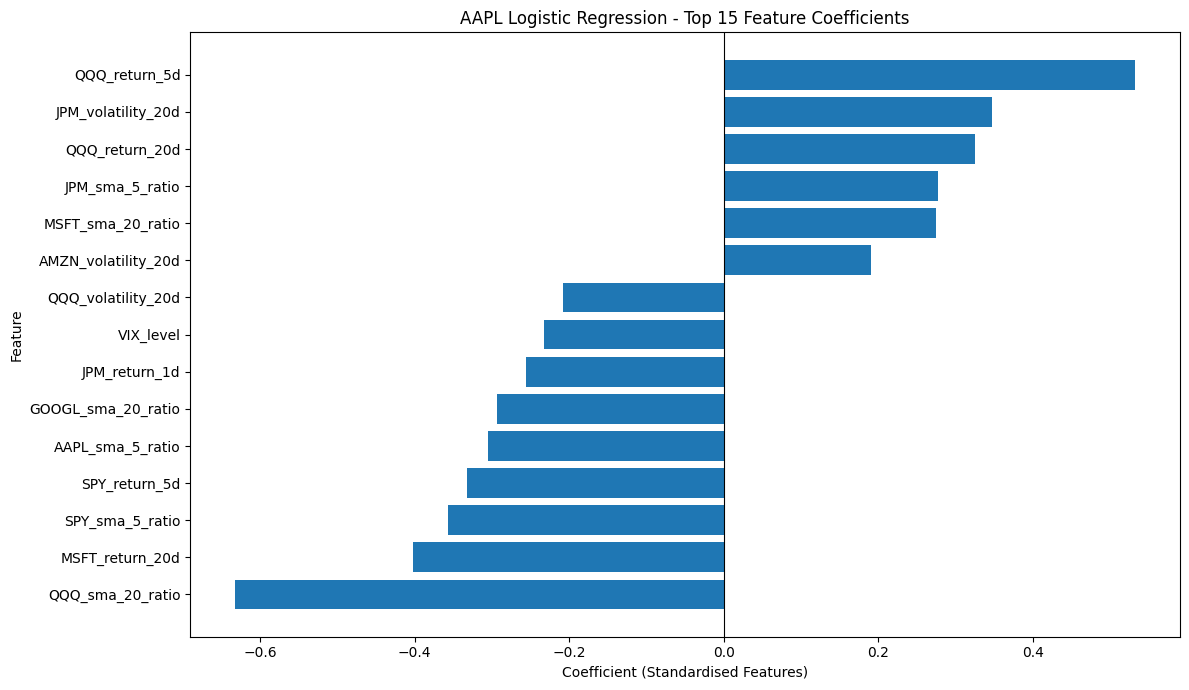

In [42]:
# ============================================================
#  AAPL LOGISTIC REGRESSION FEATURE IMPORTANCE
# ============================================================

# Extract the coefficients learned by Logistic Regression
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model_aapl.coef_[0]
})

# Calculate the absolute coefficient magnitude
feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

# Sort features from most influential to least influential
feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

# Display the 15 most influential features
print("TOP 15 AAPL LOGISTIC REGRESSION FEATURES")
print("=" * 60)

print(
    feature_importance.head(15).to_string(index=False)
)

# Plot the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("AAPL Logistic Regression - Top 15 Feature Coefficients")
plt.xlabel("Coefficient (Standardised Features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# STEP 40: SAVE AAPL LOGISTIC REGRESSION MODEL
# ============================================================

# Create a folder for classification models
classification_path = os.path.join(
    PROJECT_PATH,
    "models",
    "classification"
)

os.makedirs(classification_path, exist_ok=True)

# Save the trained Logistic Regression model
joblib.dump(
    logistic_model_aapl,
    os.path.join(
        classification_path,
        "aapl_logistic_regression.pkl"
    )
)

# Save the fitted StandardScaler
joblib.dump(
    scaler_aapl,
    os.path.join(
        classification_path,
        "aapl_logistic_scaler.pkl"
    )
)

# Confirm that both files were saved
print("AAPL Logistic Regression model saved successfully!")

print("\nSaved files:")

for filename in os.listdir(classification_path):
    print(filename)

AAPL Logistic Regression model saved successfully!

Saved files:
aapl_logistic_regression.pkl
aapl_logistic_scaler.pkl


In [44]:
# ============================================================
#  TRAIN AAPL RANDOM FOREST CLASSIFIER
# ============================================================

# Import the Random Forest classification algorithm
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest_aapl = RandomForestClassifier(
    n_estimators=300,       # Build 300 decision trees
    max_depth=8,            # Limit tree depth to reduce overfitting
    min_samples_leaf=10,    # Require at least 10 samples per leaf
    class_weight="balanced",# Account for the UP/DOWN class distribution
    random_state=42,        # Make results reproducible
    n_jobs=-1               # Use all available CPU cores
)

# Train the model using AAPL's training target
# All 63 features from the 10 assets and VIX are included
random_forest_aapl.fit(
    X_train,
    y_train_aapl
)

# Confirm successful training
print("AAPL RANDOM FOREST TRAINING COMPLETE")
print("=" * 50)

print(f"Number of trees: {random_forest_aapl.n_estimators}")
print(f"Number of input features: {random_forest_aapl.n_features_in_}")
print(f"Classes: {random_forest_aapl.classes_}")

AAPL RANDOM FOREST TRAINING COMPLETE
Number of trees: 300
Number of input features: 63
Classes: [0 1]


In [45]:
# ============================================================
# STEP 42: GENERATE RANDOM FOREST VALIDATION PREDICTIONS
# ============================================================

# Predict AAPL's next-day direction on validation data
aapl_rf_validation_predictions = random_forest_aapl.predict(
    X_validation
)

# Obtain the predicted probability of UP (class 1)
aapl_rf_validation_probabilities = random_forest_aapl.predict_proba(
    X_validation
)[:, 1]

# Create a DataFrame containing actual and predicted results
rf_validation_results = pd.DataFrame({
    "Actual Direction": y_validation_aapl,
    "Predicted Direction": aapl_rf_validation_predictions,
    "Probability of UP": aapl_rf_validation_probabilities
}, index=y_validation_aapl.index)

# Display the first 10 predictions
print("AAPL RANDOM FOREST - VALIDATION PREDICTIONS")
print("=" * 60)

print(rf_validation_results.head(10))

# Display the prediction distribution
print("\nPrediction Distribution:")
print(
    pd.Series(
        aapl_rf_validation_predictions
    ).value_counts().sort_index().rename(
        index={0: "DOWN", 1: "UP"}
    )
)

AAPL RANDOM FOREST - VALIDATION PREDICTIONS
            Actual Direction  Predicted Direction  Probability of UP
Date                                                                
2023-04-19                 0                    1           0.570336
2023-04-20                 0                    1           0.556277
2023-04-21                 1                    1           0.512967
2023-04-24                 0                    1           0.510844
2023-04-25                 0                    1           0.529566
2023-04-26                 1                    1           0.514345
2023-04-27                 1                    1           0.502883
2023-04-28                 0                    1           0.509242
2023-05-01                 0                    0           0.476355
2023-05-02                 0                    0           0.466598

Prediction Distribution:
DOWN    187
UP      256
Name: count, dtype: int64


In [46]:
# ============================================================
#  EVALUATE AAPL RANDOM FOREST CLASSIFIER
# ============================================================

# Calculate classification metrics on validation data
rf_accuracy = accuracy_score(
    y_validation_aapl,
    aapl_rf_validation_predictions
)

rf_precision = precision_score(
    y_validation_aapl,
    aapl_rf_validation_predictions,
    zero_division=0
)

rf_recall = recall_score(
    y_validation_aapl,
    aapl_rf_validation_predictions,
    zero_division=0
)

rf_f1 = f1_score(
    y_validation_aapl,
    aapl_rf_validation_predictions,
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_validation_aapl,
    aapl_rf_validation_probabilities
)

# Display the results
print("AAPL RANDOM FOREST - VALIDATION RESULTS")
print("=" * 50)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

# Display confusion matrix
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_validation_aapl,
        aapl_rf_validation_predictions
    )
)

# Display detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_validation_aapl,
        aapl_rf_validation_predictions,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

AAPL RANDOM FOREST - VALIDATION RESULTS
Accuracy:  0.5214
Precision: 0.5586
Recall:    0.5909
F1-score:  0.5743
ROC-AUC:   0.5265

Confusion Matrix:
[[ 88 113]
 [ 99 143]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.47      0.44      0.45       201
          UP       0.56      0.59      0.57       242

    accuracy                           0.52       443
   macro avg       0.51      0.51      0.51       443
weighted avg       0.52      0.52      0.52       443



AAPL CLASSIFICATION MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
  Majority Baseline    0.5463        NaN     NaN       NaN      NaN
Logistic Regression    0.5260     0.5544  0.6736    0.6082   0.5094
      Random Forest    0.5214     0.5586  0.5909    0.5743   0.5265


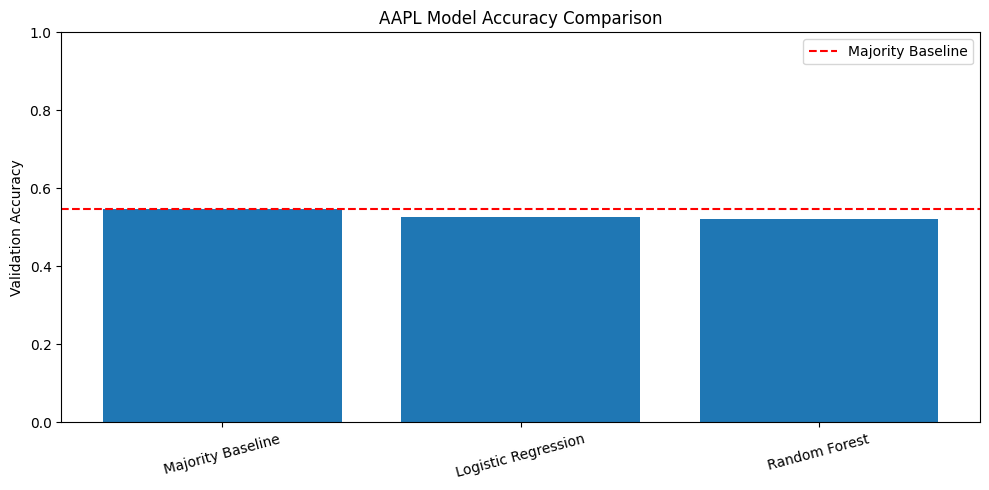

In [47]:
# ============================================================
#  COMPARE AAPL CLASSIFICATION MODELS
# ============================================================

# Create a comparison table using validation metrics
model_comparison = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        accuracy,
        rf_accuracy
    ],
    "Precision": [
        np.nan,
        precision,
        rf_precision
    ],
    "Recall": [
        np.nan,
        recall,
        rf_recall
    ],
    "F1-score": [
        np.nan,
        f1,
        rf_f1
    ],
    "ROC-AUC": [
        np.nan,
        roc_auc,
        rf_roc_auc
    ]
})

# Display the comparison table
print("AAPL CLASSIFICATION MODEL COMPARISON")
print("=" * 65)

print(model_comparison.round(4).to_string(index=False))

# Plot accuracy comparison
plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy"]
)

# Add a horizontal line representing baseline accuracy
plt.axhline(
    y=baseline_accuracy,
    linestyle="--",
    color="red",
    label="Majority Baseline"
)

plt.title("AAPL Model Accuracy Comparison")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [48]:
# ============================================================
#  IDENTIFY HIGHLY CORRELATED FEATURES
# ============================================================

# Calculate correlations using training data only
feature_correlations = X_train.corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = feature_correlations.where(
    np.triu(
        np.ones(feature_correlations.shape),
        k=1
    ).astype(bool)
)

# Identify feature pairs with correlation above 0.90
high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

# Give the resulting columns clear names
high_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

# Sort from highest to lowest correlation
high_correlations = high_correlations.sort_values(
    by="Absolute Correlation",
    ascending=False
)

# Display highly correlated feature pairs
print("HIGHLY CORRELATED FEATURES")
print("=" * 65)

print(f"Number of feature pairs above 0.90: {len(high_correlations)}")

print("\nTop 20 correlated pairs:")

print(
    high_correlations.head(20).to_string(index=False)
)

HIGHLY CORRELATED FEATURES
Number of feature pairs above 0.90: 1953

Top 20 correlated pairs:
          Feature 1            Feature 2  Absolute Correlation
 QQQ_volatility_20d   SPY_volatility_20d              0.957538
      QQQ_return_1d        SPY_return_1d              0.929968
    QQQ_sma_5_ratio      SPY_sma_5_ratio              0.919736
     QQQ_return_20d       SPY_return_20d              0.919117
      QQQ_return_5d        SPY_return_5d              0.918855
 QQQ_volatility_20d  MSFT_volatility_20d              0.918301
   QQQ_sma_20_ratio     SPY_sma_20_ratio              0.917773
AAPL_volatility_20d   QQQ_volatility_20d              0.898350
 SPY_volatility_20d  MSFT_volatility_20d              0.896785
AAPL_volatility_20d  MSFT_volatility_20d              0.883268
      QQQ_return_1d       MSFT_return_1d              0.878605
 SPY_volatility_20d   JPM_volatility_20d              0.876554
    AAPL_return_20d    AAPL_sma_20_ratio              0.870262
AAPL_volatility_20d   SP

In [49]:
# ============================================================
# STEP 46: FILTER FEATURES WITH CORRELATION ABOVE 0.90
# ============================================================

# Set the correlation threshold
correlation_threshold = 0.90

# Filter feature pairs using the specified threshold
high_correlations_filtered = high_correlations[
    high_correlations["Absolute Correlation"] > correlation_threshold
].copy()

# Sort from highest to lowest correlation
high_correlations_filtered = high_correlations_filtered.sort_values(
    by="Absolute Correlation",
    ascending=False
)

# Display the corrected results
print("HIGHLY CORRELATED FEATURE PAIRS")
print("=" * 65)

print(
    f"Number of pairs above {correlation_threshold}: "
    f"{len(high_correlations_filtered)}"
)

print("\nCorrelated feature pairs:")

print(
    high_correlations_filtered.to_string(index=False)
)

HIGHLY CORRELATED FEATURE PAIRS
Number of pairs above 0.9: 7

Correlated feature pairs:
         Feature 1           Feature 2  Absolute Correlation
QQQ_volatility_20d  SPY_volatility_20d              0.957538
     QQQ_return_1d       SPY_return_1d              0.929968
   QQQ_sma_5_ratio     SPY_sma_5_ratio              0.919736
    QQQ_return_20d      SPY_return_20d              0.919117
     QQQ_return_5d       SPY_return_5d              0.918855
QQQ_volatility_20d MSFT_volatility_20d              0.918301
  QQQ_sma_20_ratio    SPY_sma_20_ratio              0.917773


TOP 15 FEATURES CORRELATED WITH AAPL DIRECTION
SPY_return_1d          -0.061804
JPM_return_1d          -0.052907
AAPL_return_1d         -0.052797
QQQ_return_1d          -0.050062
MSFT_return_1d         -0.050048
SPY_sma_5_ratio        -0.041589
MSFT_sma_5_ratio       -0.037275
MSFT_return_20d        -0.036232
AAPL_sma_5_ratio       -0.035830
MSFT_sma_20_ratio      -0.034516
QQQ_sma_5_ratio        -0.031516
GOOGL_volatility_20d   -0.029643
GOOGL_return_1d        -0.027853
TSLA_return_1d         -0.027429
NVDA_return_20d         0.026626


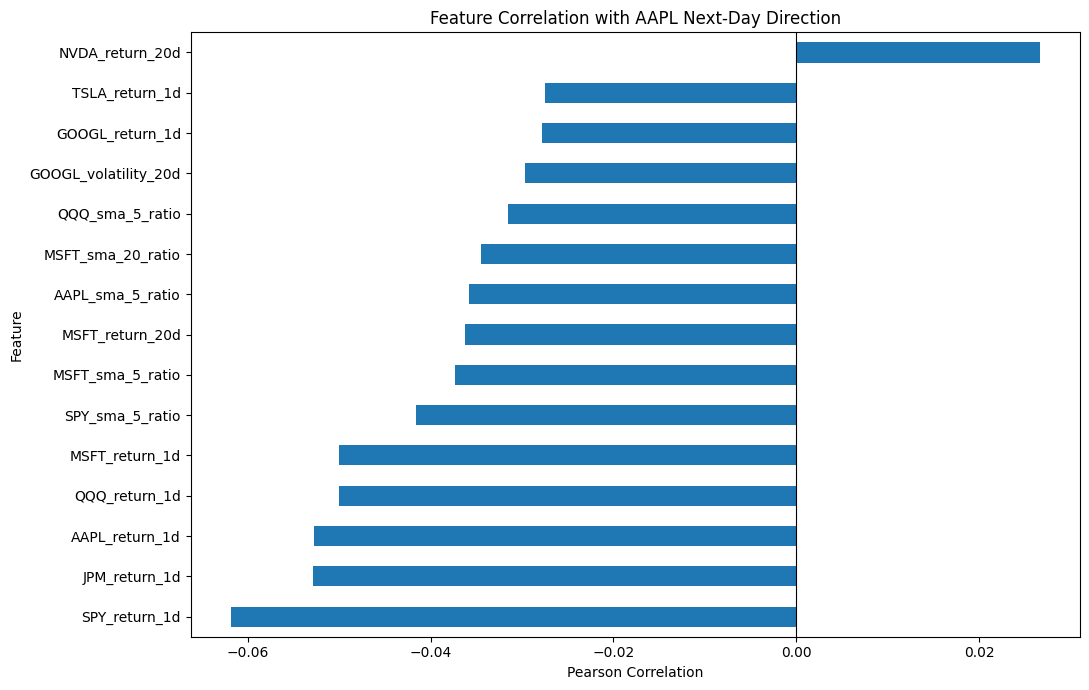

In [50]:
# ============================================================
# CORRELATION BETWEEN FEATURES AND AAPL DIRECTION
# ============================================================

# Combine training features with the AAPL training target
correlation_data = X_train.copy()

correlation_data["AAPL_direction"] = y_train_aapl

# Calculate correlations with the AAPL prediction target
target_correlations = (
    correlation_data.corr()["AAPL_direction"]
    .drop("AAPL_direction")
    .sort_values(key=abs, ascending=False)
)

# Display the 15 strongest correlations
print("TOP 15 FEATURES CORRELATED WITH AAPL DIRECTION")
print("=" * 65)

print(target_correlations.head(15).to_string())

# Plot the strongest correlations
plt.figure(figsize=(11, 7))

target_correlations.head(15).sort_values().plot(
    kind="barh"
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Feature Correlation with AAPL Next-Day Direction")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

AAPL TRAINING TARGET DISTRIBUTION
DOWN observations: 978
UP observations:   1089

Class percentages:
DOWN: 47.31%
UP:   52.69%


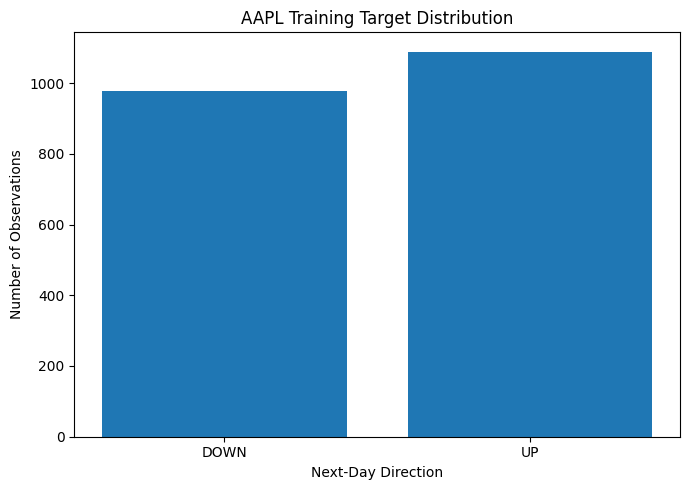

In [51]:
#  ANALYSE AAPL TRAINING TARGET DISTRIBUTION
# ============================================================

# Count DOWN and UP observations in training data
training_direction_counts = y_train_aapl.value_counts().sort_index()

# Calculate percentages
training_direction_percentages = (
    y_train_aapl.value_counts(normalize=True).sort_index() * 100
)

# Display the distribution
print("AAPL TRAINING TARGET DISTRIBUTION")
print("=" * 50)

print(f"DOWN observations: {training_direction_counts.get(0, 0)}")
print(f"UP observations:   {training_direction_counts.get(1, 0)}")

print("\nClass percentages:")

print(f"DOWN: {training_direction_percentages.get(0, 0):.2f}%")
print(f"UP:   {training_direction_percentages.get(1, 0):.2f}%")

# Plot the class distribution
plt.figure(figsize=(7, 5))

plt.bar(
    ["DOWN", "UP"],
    [
        training_direction_counts.get(0, 0),
        training_direction_counts.get(1, 0)
    ]
)

plt.title("AAPL Training Target Distribution")
plt.xlabel("Next-Day Direction")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [52]:
# ============================================================
#  SET UP WALK-FORWARD VALIDATION
# ============================================================

# Import the time-series cross-validation tool
from sklearn.model_selection import TimeSeriesSplit

# Combine the original training and validation datasets
# We will use these observations for walk-forward experiments.
# The final test dataset is NOT included.
X_development = pd.concat(
    [X_train, X_validation],
    axis=0
)

y_development_aapl = pd.concat(
    [y_train_aapl, y_validation_aapl],
    axis=0
)

# Create five chronological validation folds
# Each fold validates on the next 250 trading observations.
# Earlier observations become the training history.
tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=250
)

# Display the date ranges for each fold
print("AAPL WALK-FORWARD VALIDATION SETUP")
print("=" * 65)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Select training and validation dates for this fold
    train_dates = X_development.index[train_idx]
    val_dates = X_development.index[val_idx]

    print(f"\nFold {fold}")
    print(
        f"Training:   {train_dates.min().date()} "
        f"to {train_dates.max().date()} "
        f"({len(train_idx)} rows)"
    )
    print(
        f"Validation: {val_dates.min().date()} "
        f"to {val_dates.max().date()} "
        f"({len(val_idx)} rows)"
    )

# Confirm that the final test set is separate
print("\nFinal test observations (untouched):", len(X_test))

AAPL WALK-FORWARD VALIDATION SETUP

Fold 1
Training:   2015-02-02 to 2020-02-03 (1260 rows)
Validation: 2020-02-04 to 2021-01-29 (250 rows)

Fold 2
Training:   2015-02-02 to 2021-01-29 (1510 rows)
Validation: 2021-02-01 to 2022-01-26 (250 rows)

Fold 3
Training:   2015-02-02 to 2022-01-26 (1760 rows)
Validation: 2022-01-27 to 2023-01-25 (250 rows)

Fold 4
Training:   2015-02-02 to 2023-01-25 (2010 rows)
Validation: 2023-01-26 to 2024-01-24 (250 rows)

Fold 5
Training:   2015-02-02 to 2024-01-24 (2260 rows)
Validation: 2024-01-25 to 2025-01-23 (250 rows)

Final test observations (untouched): 444


In [53]:
# ============================================================
#  WALK-FORWARD LOGISTIC REGRESSION EVALUATION
# ============================================================

# Create a list to store results from each validation fold
walk_forward_results = []

# Loop through all five chronological folds
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Select training and validation features
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    # Select matching AAPL direction targets
    y_fold_train = y_development_aapl.iloc[train_idx]
    y_fold_val = y_development_aapl.iloc[val_idx]

    # Create a fresh scaler for this fold
    fold_scaler = StandardScaler()

    # Fit scaler only on training data
    X_fold_train_scaled = fold_scaler.fit_transform(
        X_fold_train
    )

    # Transform validation data without refitting
    X_fold_val_scaled = fold_scaler.transform(
        X_fold_val
    )

    # Create a fresh Logistic Regression model
    fold_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    # Train the model
    fold_model.fit(
        X_fold_train_scaled,
        y_fold_train
    )

    # Generate validation predictions
    fold_predictions = fold_model.predict(
        X_fold_val_scaled
    )

    # Calculate validation probabilities
    fold_probabilities = fold_model.predict_proba(
        X_fold_val_scaled
    )[:, 1]

    # Calculate evaluation metrics
    fold_accuracy = accuracy_score(
        y_fold_val,
        fold_predictions
    )

    fold_precision = precision_score(
        y_fold_val,
        fold_predictions,
        zero_division=0
    )

    fold_recall = recall_score(
        y_fold_val,
        fold_predictions,
        zero_division=0
    )

    fold_f1 = f1_score(
        y_fold_val,
        fold_predictions,
        zero_division=0
    )

    fold_roc_auc = roc_auc_score(
        y_fold_val,
        fold_probabilities
    )

    # Save this fold's results
    walk_forward_results.append({
        "Fold": fold,
        "Accuracy": fold_accuracy,
        "Precision": fold_precision,
        "Recall": fold_recall,
        "F1-score": fold_f1,
        "ROC-AUC": fold_roc_auc
    })

    # Display progress
    print(
        f"Fold {fold} completed | "
        f"Accuracy: {fold_accuracy:.4f} | "
        f"ROC-AUC: {fold_roc_auc:.4f}"
    )

# Convert results into a DataFrame
walk_forward_results_df = pd.DataFrame(
    walk_forward_results
)

# Display the complete results
print("\nLOGISTIC REGRESSION WALK-FORWARD RESULTS")
print("=" * 65)

print(walk_forward_results_df.round(4).to_string(index=False))

# Calculate average performance across all folds
print("\nAVERAGE VALIDATION PERFORMANCE")
print("=" * 40)

print(
    walk_forward_results_df[
        ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
    ].mean().round(4)
)

Fold 1 completed | Accuracy: 0.5600 | ROC-AUC: 0.5694
Fold 2 completed | Accuracy: 0.4640 | ROC-AUC: 0.4519
Fold 3 completed | Accuracy: 0.5080 | ROC-AUC: 0.4989
Fold 4 completed | Accuracy: 0.5200 | ROC-AUC: 0.4926
Fold 5 completed | Accuracy: 0.5560 | ROC-AUC: 0.5185

LOGISTIC REGRESSION WALK-FORWARD RESULTS
 Fold  Accuracy  Precision  Recall  F1-score  ROC-AUC
    1     0.560     0.5887  0.6148    0.6014   0.5694
    2     0.464     0.4809  0.4884    0.4846   0.4519
    3     0.508     0.5027  0.7419    0.5993   0.4989
    4     0.520     0.5540  0.5704    0.5620   0.4926
    5     0.556     0.5729  0.8143    0.6726   0.5185

AVERAGE VALIDATION PERFORMANCE
Accuracy     0.5216
Precision    0.5398
Recall       0.6460
F1-score     0.5840
ROC-AUC      0.5062
dtype: float64


In [54]:
# ============================================================
# STEP 51: COMPARE LOGISTIC REGRESSION WITH BASELINE
# ACROSS ALL WALK-FORWARD FOLDS
# ============================================================

# Create a list to store baseline comparison results
baseline_fold_results = []

# Repeat the chronological fold evaluation
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Extract actual validation targets
    y_fold_val = y_development_aapl.iloc[val_idx]

    # Find the majority class using training data only
    majority_class_fold = (
        y_development_aapl.iloc[train_idx].mode()[0]
    )

    # Predict the training majority class for every validation row
    baseline_fold_predictions = np.full(
        shape=len(y_fold_val),
        fill_value=majority_class_fold
    )

    # Calculate baseline validation accuracy
    baseline_fold_accuracy = accuracy_score(
        y_fold_val,
        baseline_fold_predictions
    )

    # Retrieve Logistic Regression accuracy for this fold
    logistic_fold_accuracy = (
        walk_forward_results_df.loc[
            walk_forward_results_df["Fold"] == fold,
            "Accuracy"
        ].iloc[0]
    )

    # Calculate improvement over the baseline
    accuracy_difference = (
        logistic_fold_accuracy - baseline_fold_accuracy
    )

    # Save the results
    baseline_fold_results.append({
        "Fold": fold,
        "Majority Class": majority_class_fold,
        "Baseline Accuracy": baseline_fold_accuracy,
        "Logistic Accuracy": logistic_fold_accuracy,
        "Improvement": accuracy_difference
    })

# Create a comparison DataFrame
baseline_comparison_df = pd.DataFrame(
    baseline_fold_results
)

# Display the comparison
print("WALK-FORWARD BASELINE COMPARISON")
print("=" * 75)

print(
    baseline_comparison_df.round(4).to_string(index=False)
)

# Calculate average improvement
average_improvement = baseline_comparison_df[
    "Improvement"
].mean()

print("\nAverage accuracy improvement over baseline:")
print(f"{average_improvement * 100:.2f} percentage points")

WALK-FORWARD BASELINE COMPARISON
 Fold  Majority Class  Baseline Accuracy  Logistic Accuracy  Improvement
    1               1              0.540              0.560        0.020
    2               1              0.516              0.464       -0.052
    3               1              0.496              0.508        0.012
    4               1              0.540              0.520       -0.020
    5               1              0.560              0.556       -0.004

Average accuracy improvement over baseline:
-0.88 percentage points


In [55]:
# ============================================================
# EXAMINE PREDICTION DISTRIBUTION
# ACROSS WALK-FORWARD FOLDS
# ============================================================

# Create a list to store prediction distribution results
prediction_distribution = []

# Repeat the five chronological validation folds
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Select training and validation data
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development_aapl.iloc[train_idx]

    # Create a fresh scaler for this fold
    fold_scaler = StandardScaler()

    # Fit scaler only on training data
    X_fold_train_scaled = fold_scaler.fit_transform(
        X_fold_train
    )

    # Transform validation data
    X_fold_val_scaled = fold_scaler.transform(
        X_fold_val
    )

    # Train Logistic Regression
    fold_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    fold_model.fit(
        X_fold_train_scaled,
        y_fold_train
    )

    # Generate validation predictions
    fold_predictions = fold_model.predict(
        X_fold_val_scaled
    )

    # Count DOWN and UP predictions
    down_predictions = (fold_predictions == 0).sum()
    up_predictions = (fold_predictions == 1).sum()

    # Calculate prediction percentages
    total_predictions = len(fold_predictions)

    prediction_distribution.append({
        "Fold": fold,
        "DOWN Predictions": down_predictions,
        "UP Predictions": up_predictions,
        "DOWN Percentage": down_predictions / total_predictions * 100,
        "UP Percentage": up_predictions / total_predictions * 100
    })

# Convert results into a DataFrame
prediction_distribution_df = pd.DataFrame(
    prediction_distribution
)

# Display results
print("PREDICTION DISTRIBUTION ACROSS FOLDS")
print("=" * 75)

print(
    prediction_distribution_df.round(2).to_string(index=False)
)

PREDICTION DISTRIBUTION ACROSS FOLDS
 Fold  DOWN Predictions  UP Predictions  DOWN Percentage  UP Percentage
    1               109             141             43.6           56.4
    2               119             131             47.6           52.4
    3                67             183             26.8           73.2
    4               111             139             44.4           55.6
    5                51             199             20.4           79.6


In [56]:
# ============================================================
#  COMPARE ACTUAL AND PREDICTED DIRECTIONS
# ACROSS WALK-FORWARD FOLDS
# ============================================================

# Create a list to store comparison results
direction_comparison = []

# Repeat the chronological validation folds
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Select training and validation data
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development_aapl.iloc[train_idx]
    y_fold_val = y_development_aapl.iloc[val_idx]

    # Scale features using training data only
    fold_scaler = StandardScaler()

    X_fold_train_scaled = fold_scaler.fit_transform(
        X_fold_train
    )

    X_fold_val_scaled = fold_scaler.transform(
        X_fold_val
    )

    # Train Logistic Regression
    fold_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    fold_model.fit(
        X_fold_train_scaled,
        y_fold_train
    )

    # Generate predictions
    fold_predictions = fold_model.predict(
        X_fold_val_scaled
    )

    # Calculate actual and predicted class percentages
    actual_up = (y_fold_val == 1).mean() * 100
    actual_down = (y_fold_val == 0).mean() * 100

    predicted_up = (fold_predictions == 1).mean() * 100
    predicted_down = (fold_predictions == 0).mean() * 100

    # Store results
    direction_comparison.append({
        "Fold": fold,
        "Actual DOWN %": actual_down,
        "Predicted DOWN %": predicted_down,
        "Actual UP %": actual_up,
        "Predicted UP %": predicted_up
    })

# Create comparison DataFrame
direction_comparison_df = pd.DataFrame(
    direction_comparison
)

# Display results
print("ACTUAL VS PREDICTED DIRECTION DISTRIBUTION")
print("=" * 85)

print(
    direction_comparison_df.round(2).to_string(index=False)
)

ACTUAL VS PREDICTED DIRECTION DISTRIBUTION
 Fold  Actual DOWN %  Predicted DOWN %  Actual UP %  Predicted UP %
    1           46.0              43.6         54.0            56.4
    2           48.4              47.6         51.6            52.4
    3           50.4              26.8         49.6            73.2
    4           46.0              44.4         54.0            55.6
    5           44.0              20.4         56.0            79.6


In [57]:
# ============================================================
#  ANALYSE PREDICTION PROBABILITIES
# ACROSS WALK-FORWARD FOLDS
# ============================================================

# Create a list to store probability results
probability_results = []

# Repeat the chronological validation folds
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Select training and validation data
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development_aapl.iloc[train_idx]

    # Scale using training data only
    fold_scaler = StandardScaler()

    X_fold_train_scaled = fold_scaler.fit_transform(
        X_fold_train
    )

    X_fold_val_scaled = fold_scaler.transform(
        X_fold_val
    )

    # Train Logistic Regression
    fold_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    fold_model.fit(
        X_fold_train_scaled,
        y_fold_train
    )

    # Calculate probability of UP movement
    up_probabilities = fold_model.predict_proba(
        X_fold_val_scaled
    )[:, 1]

    # Calculate probability statistics
    probability_results.append({
        "Fold": fold,
        "Average UP Probability": up_probabilities.mean(),
        "Minimum UP Probability": up_probabilities.min(),
        "Maximum UP Probability": up_probabilities.max(),
        "Average Confidence": np.maximum(
            up_probabilities,
            1 - up_probabilities
        ).mean()
    })

# Convert results into a DataFrame
probability_results_df = pd.DataFrame(
    probability_results
)

# Display probability statistics as percentages
print("PREDICTION PROBABILITY ANALYSIS")
print("=" * 85)

print(
    (probability_results_df.set_index("Fold") * 100)
    .round(2)
    .to_string()
)

PREDICTION PROBABILITY ANALYSIS
      Average UP Probability  Minimum UP Probability  Maximum UP Probability  Average Confidence
Fold                                                                                            
1                      53.68                    7.54                   99.42               64.99
2                      50.29                   23.84                   74.79               59.49
3                      57.83                   22.66                   93.04               62.69
4                      51.14                   27.51                   73.84               56.99
5                      57.77                   24.62                   81.75               60.28


PROBABILITY CALIBRATION RESULTS
Brier Score: 0.2640

CALIBRATION CURVE VALUES
 Average Predicted Probability  Actual UP Frequency
                        0.0754               0.0000
                        0.1593               0.2857
                        0.2633               0.5143
                        0.3585               0.6077
                        0.4555               0.4754
                        0.5524               0.5515
                        0.6416               0.5142
                        0.7387               0.5714
                        0.8356               0.5238
                        0.9457               0.6364


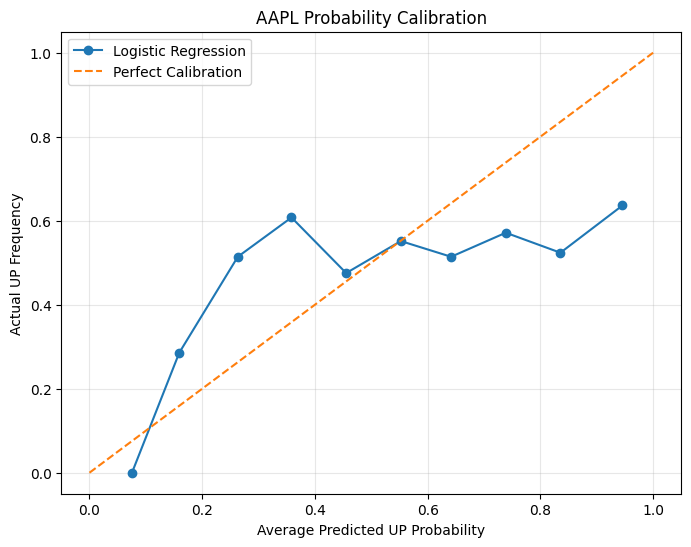

In [58]:
# ============================================================
#  EVALUATE PROBABILITY CALIBRATION
# USING WALK-FORWARD VALIDATION
# ============================================================

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Store predictions and actual outcomes from all folds
all_actual_values = []
all_predicted_probabilities = []

# Repeat chronological validation
for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development),
    start=1
):

    # Select training and validation data
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development_aapl.iloc[train_idx]
    y_fold_val = y_development_aapl.iloc[val_idx]

    # Fit scaler using training data only
    fold_scaler = StandardScaler()

    X_fold_train_scaled = fold_scaler.fit_transform(
        X_fold_train
    )

    X_fold_val_scaled = fold_scaler.transform(
        X_fold_val
    )

    # Train Logistic Regression
    fold_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    fold_model.fit(
        X_fold_train_scaled,
        y_fold_train
    )

    # Obtain predicted UP probabilities
    fold_probabilities = fold_model.predict_proba(
        X_fold_val_scaled
    )[:, 1]

    # Store actual outcomes and probabilities
    all_actual_values.extend(y_fold_val.tolist())

    all_predicted_probabilities.extend(
        fold_probabilities.tolist()
    )

# Convert stored results into NumPy arrays
all_actual_values = np.array(all_actual_values)

all_predicted_probabilities = np.array(
    all_predicted_probabilities
)

# Calculate Brier score
brier_score = brier_score_loss(
    all_actual_values,
    all_predicted_probabilities
)

# Calculate calibration curve
actual_fraction, predicted_mean = calibration_curve(
    all_actual_values,
    all_predicted_probabilities,
    n_bins=10,
    strategy="uniform"
)

# Display Brier score
print("PROBABILITY CALIBRATION RESULTS")
print("=" * 60)

print(f"Brier Score: {brier_score:.4f}")

print("\nCALIBRATION CURVE VALUES")
print("=" * 60)

calibration_results = pd.DataFrame({
    "Average Predicted Probability": predicted_mean,
    "Actual UP Frequency": actual_fraction
})

print(calibration_results.round(4).to_string(index=False))

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    predicted_mean,
    actual_fraction,
    marker="o",
    label="Logistic Regression"
)

# Perfect calibration reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Average Predicted UP Probability")
plt.ylabel("Actual UP Frequency")

plt.title("AAPL Probability Calibration")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [59]:
# ============================================================
# SAVE LOGISTIC REGRESSION EXPERIMENT RESULTS
# ============================================================

# Define the results folder
results_path = os.path.join(
    PROJECT_PATH,
    "results"
)

# Create the folder if it does not exist
os.makedirs(results_path, exist_ok=True)

# Save walk-forward performance
walk_forward_results_df.to_csv(
    os.path.join(
        results_path,
        "aapl_logistic_walk_forward_results.csv"
    ),
    index=False
)

# Save baseline comparison
baseline_comparison_df.to_csv(
    os.path.join(
        results_path,
        "aapl_logistic_baseline_comparison.csv"
    ),
    index=False
)

# Save prediction distribution
prediction_distribution_df.to_csv(
    os.path.join(
        results_path,
        "aapl_logistic_prediction_distribution.csv"
    ),
    index=False
)

# Save actual versus predicted distribution
direction_comparison_df.to_csv(
    os.path.join(
        results_path,
        "aapl_logistic_direction_comparison.csv"
    ),
    index=False
)

# Save probability calibration results
calibration_results.to_csv(
    os.path.join(
        results_path,
        "aapl_logistic_calibration_results.csv"
    ),
    index=False
)

# Save Brier score separately
brier_results = pd.DataFrame({
    "Model": ["AAPL Logistic Regression"],
    "Brier Score": [brier_score]
})

brier_results.to_csv(
    os.path.join(
        results_path,
        "aapl_logistic_brier_score.csv"
    ),
    index=False
)

# Confirm saved files
print("EXPERIMENT RESULTS SAVED SUCCESSFULLY")
print("=" * 55)

for filename in os.listdir(results_path):
    if filename.startswith("aapl_logistic_"):
        print(filename)

#Conclusion: The model has not demonstrated reliable predictive ability beyond a simple baseline.

EXPERIMENT RESULTS SAVED SUCCESSFULLY
aapl_logistic_walk_forward_results.csv
aapl_logistic_baseline_comparison.csv
aapl_logistic_prediction_distribution.csv
aapl_logistic_direction_comparison.csv
aapl_logistic_calibration_results.csv
aapl_logistic_brier_score.csv


In [60]:
# ============================================================
#  IMPORT RANDOM FOREST EXPERIMENT TOOLS
# ============================================================

# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Import tools for chronological cross-validation
from sklearn.model_selection import TimeSeriesSplit

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Confirm imports
print("Random Forest experiment tools imported successfully!")

Random Forest experiment tools imported successfully!


In [61]:
# ============================================================
# PREPARE DATA FOR RANDOM FOREST EXPERIMENTS
# ============================================================

# Combine training and validation features
X_development = pd.concat([
    X_train,
    X_validation
])

# Combine training and validation AAPL targets
y_development_aapl = pd.concat([
    y_train["AAPL_direction"],
    y_validation["AAPL_direction"]
])

# Confirm the development dataset dimensions
print("Development Features:", X_development.shape)
print("Development Target:", y_development_aapl.shape)

# Display the development date range
print("\nDevelopment Period:")
print("Start:", X_development.index.min())
print("End:", X_development.index.max())

# Confirm the final test dataset remains separate
print("\nFinal Test Dataset:", X_test.shape)
print("Final Test Period:")
print("Start:", X_test.index.min())
print("End:", X_test.index.max())

# Verify that feature and target dates match
assert X_development.index.equals(
    y_development_aapl.index
)

print("\nData preparation successful!")

Development Features: (2510, 63)
Development Target: (2510,)

Development Period:
Start: 2015-02-02 00:00:00
End: 2025-01-23 00:00:00

Final Test Dataset: (444, 63)
Final Test Period:
Start: 2025-01-24 00:00:00
End: 2026-10-29 00:00:00

Data preparation successful!


In [62]:
# ============================================================
# PREPARE CHRONOLOGICAL CROSS-VALIDATION
# ============================================================

# Create five chronological validation folds
rf_tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=250
)

# Display the date ranges for each fold
print("RANDOM FOREST WALK-FORWARD FOLDS")
print("=" * 65)

for fold, (train_idx, val_idx) in enumerate(
    rf_tscv.split(X_development),
    start=1
):

    # Identify training and validation periods
    train_start = X_development.index[train_idx[0]]
    train_end = X_development.index[train_idx[-1]]

    val_start = X_development.index[val_idx[0]]
    val_end = X_development.index[val_idx[-1]]

    # Display fold information
    print(f"\nFold {fold}")

    print(
        f"Training: {train_start.date()} to {train_end.date()}"
    )

    print(
        f"Validation: {val_start.date()} to {val_end.date()}"
    )

    print(f"Training observations: {len(train_idx)}")
    print(f"Validation observations: {len(val_idx)}")

RANDOM FOREST WALK-FORWARD FOLDS

Fold 1
Training: 2015-02-02 to 2020-02-03
Validation: 2020-02-04 to 2021-01-29
Training observations: 1260
Validation observations: 250

Fold 2
Training: 2015-02-02 to 2021-01-29
Validation: 2021-02-01 to 2022-01-26
Training observations: 1510
Validation observations: 250

Fold 3
Training: 2015-02-02 to 2022-01-26
Validation: 2022-01-27 to 2023-01-25
Training observations: 1760
Validation observations: 250

Fold 4
Training: 2015-02-02 to 2023-01-25
Validation: 2023-01-26 to 2024-01-24
Training observations: 2010
Validation observations: 250

Fold 5
Training: 2015-02-02 to 2024-01-24
Validation: 2024-01-25 to 2025-01-23
Training observations: 2260
Validation observations: 250


In [63]:
# ============================================================
# DEFINE RANDOM FOREST HYPERPARAMETER CONFIGURATIONS
# ============================================================

# Create a selection of Random Forest configurations
rf_configurations = [
    {
        "n_estimators": 200,
        "max_depth": 5,
        "min_samples_split": 20,
        "min_samples_leaf": 10
    },
    {
        "n_estimators": 300,
        "max_depth": 8,
        "min_samples_split": 20,
        "min_samples_leaf": 10
    },
    {
        "n_estimators": 500,
        "max_depth": 10,
        "min_samples_split": 20,
        "min_samples_leaf": 10
    },
    {
        "n_estimators": 300,
        "max_depth": 12,
        "min_samples_split": 10,
        "min_samples_leaf": 5
    },
    {
        "n_estimators": 500,
        "max_depth": None,
        "min_samples_split": 20,
        "min_samples_leaf": 10
    }
]

# Display the configurations
print("RANDOM FOREST CONFIGURATIONS")
print("=" * 65)

for number, configuration in enumerate(
    rf_configurations,
    start=1
):
    print(f"\nConfiguration {number}")

    for parameter, value in configuration.items():
        print(f"{parameter}: {value}")

# Confirm the number of configurations
print("\nTotal configurations:", len(rf_configurations))

RANDOM FOREST CONFIGURATIONS

Configuration 1
n_estimators: 200
max_depth: 5
min_samples_split: 20
min_samples_leaf: 10

Configuration 2
n_estimators: 300
max_depth: 8
min_samples_split: 20
min_samples_leaf: 10

Configuration 3
n_estimators: 500
max_depth: 10
min_samples_split: 20
min_samples_leaf: 10

Configuration 4
n_estimators: 300
max_depth: 12
min_samples_split: 10
min_samples_leaf: 5

Configuration 5
n_estimators: 500
max_depth: None
min_samples_split: 20
min_samples_leaf: 10

Total configurations: 5


In [64]:
# ============================================================
# EVALUATE RANDOM FOREST CONFIGURATIONS
# ============================================================

# Create a list to store all experiment results
rf_experiment_results = []

# Loop through each hyperparameter configuration
for config_number, configuration in enumerate(
    rf_configurations,
    start=1
):

    print(f"\nEvaluating Configuration {config_number}")
    print("-" * 55)

    # Evaluate the configuration across five chronological folds
    for fold, (train_idx, val_idx) in enumerate(
        rf_tscv.split(X_development),
        start=1
    ):

        # Select training and validation observations
        X_fold_train = X_development.iloc[train_idx]
        X_fold_val = X_development.iloc[val_idx]

        y_fold_train = y_development_aapl.iloc[train_idx]
        y_fold_val = y_development_aapl.iloc[val_idx]

        # Create the Random Forest model
        rf_model = RandomForestClassifier(
            **configuration,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        # Train the model using historical training data
        rf_model.fit(
            X_fold_train,
            y_fold_train
        )

        # Generate validation predictions
        fold_predictions = rf_model.predict(
            X_fold_val
        )

        # Generate predicted probabilities for ROC-AUC
        fold_probabilities = rf_model.predict_proba(
            X_fold_val
        )[:, 1]

        # Calculate evaluation metrics
        fold_accuracy = accuracy_score(
            y_fold_val,
            fold_predictions
        )

        fold_precision = precision_score(
            y_fold_val,
            fold_predictions,
            zero_division=0
        )

        fold_recall = recall_score(
            y_fold_val,
            fold_predictions,
            zero_division=0
        )

        fold_f1 = f1_score(
            y_fold_val,
            fold_predictions,
            zero_division=0
        )

        fold_roc_auc = roc_auc_score(
            y_fold_val,
            fold_probabilities
        )

        # Save the results
        rf_experiment_results.append({
            "Configuration": config_number,
            "Fold": fold,
            "Accuracy": fold_accuracy,
            "Precision": fold_precision,
            "Recall": fold_recall,
            "F1": fold_f1,
            "ROC-AUC": fold_roc_auc
        })

        # Display progress
        print(
            f"Fold {fold} completed | "
            f"Accuracy: {fold_accuracy:.4f} | "
            f"ROC-AUC: {fold_roc_auc:.4f}"
        )

# Convert results into a DataFrame
rf_experiment_results_df = pd.DataFrame(
    rf_experiment_results
)

# Display completion message
print("\nAll Random Forest experiments completed!")

print(
    "Total evaluations:",
    len(rf_experiment_results_df)
)


Evaluating Configuration 1
-------------------------------------------------------
Fold 1 completed | Accuracy: 0.5480 | ROC-AUC: 0.5556
Fold 2 completed | Accuracy: 0.4800 | ROC-AUC: 0.4601
Fold 3 completed | Accuracy: 0.5280 | ROC-AUC: 0.4972
Fold 4 completed | Accuracy: 0.5480 | ROC-AUC: 0.5172
Fold 5 completed | Accuracy: 0.5200 | ROC-AUC: 0.5082

Evaluating Configuration 2
-------------------------------------------------------
Fold 1 completed | Accuracy: 0.5440 | ROC-AUC: 0.5487
Fold 2 completed | Accuracy: 0.4640 | ROC-AUC: 0.4256
Fold 3 completed | Accuracy: 0.5120 | ROC-AUC: 0.4980
Fold 4 completed | Accuracy: 0.5000 | ROC-AUC: 0.5264
Fold 5 completed | Accuracy: 0.5160 | ROC-AUC: 0.4972

Evaluating Configuration 3
-------------------------------------------------------
Fold 1 completed | Accuracy: 0.5560 | ROC-AUC: 0.5668
Fold 2 completed | Accuracy: 0.4600 | ROC-AUC: 0.4383
Fold 3 completed | Accuracy: 0.5200 | ROC-AUC: 0.5028
Fold 4 completed | Accuracy: 0.4880 | ROC-AUC:

In [65]:
# ============================================================
# COMPARE AVERAGE RANDOM FOREST PERFORMANCE
# ============================================================

# Group results by hyperparameter configuration
rf_summary = (
    rf_experiment_results_df
    .groupby("Configuration")
    .agg({
        "Accuracy": "mean",
        "Precision": "mean",
        "Recall": "mean",
        "F1": "mean",
        "ROC-AUC": "mean"
    })
    .reset_index()
)

# Sort configurations by average ROC-AUC
rf_summary = rf_summary.sort_values(
    by="ROC-AUC",
    ascending=False
)

# Display average performance
print("RANDOM FOREST CONFIGURATION COMPARISON")
print("=" * 85)

print(
    rf_summary.round(4).to_string(index=False)
)

# Identify the configuration with the highest average ROC-AUC
best_configuration_number = int(
    rf_summary.iloc[0]["Configuration"]
)

print("\nBest configuration by average ROC-AUC:")
print(best_configuration_number)

# Display its hyperparameters
print("\nSelected hyperparameters:")

print(
    rf_configurations[
        best_configuration_number - 1
    ]
)

RANDOM FOREST CONFIGURATION COMPARISON
 Configuration  Accuracy  Precision  Recall     F1  ROC-AUC
             1    0.5248     0.5460  0.6397 0.5863   0.5077
             4    0.5144     0.5366  0.6220 0.5733   0.5076
             3    0.5064     0.5292  0.6175 0.5674   0.5049
             5    0.5048     0.5296  0.6107 0.5650   0.5000
             2    0.5072     0.5312  0.5976 0.5576   0.4992

Best configuration by average ROC-AUC:
1

Selected hyperparameters:
{'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 20, 'min_samples_leaf': 10}


In [66]:
# ============================================================
# COMPARE BEST RANDOM FOREST WITH BASELINE
# ============================================================

# Select the best-performing configuration
best_rf_config = rf_configurations[
    best_configuration_number - 1
]

# Store baseline comparison results
rf_baseline_results = []

# Evaluate the selected model across chronological folds
for fold, (train_idx, val_idx) in enumerate(
    rf_tscv.split(X_development),
    start=1
):

    # Select training and validation data
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development_aapl.iloc[train_idx]
    y_fold_val = y_development_aapl.iloc[val_idx]

    # Train Random Forest using the selected configuration
    rf_model = RandomForestClassifier(
        **best_rf_config,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(
        X_fold_train,
        y_fold_train
    )

    # Generate validation predictions
    rf_predictions = rf_model.predict(
        X_fold_val
    )

    # Calculate Random Forest accuracy
    rf_accuracy = accuracy_score(
        y_fold_val,
        rf_predictions
    )

    # Determine majority class using training data only
    majority_class = y_fold_train.mode()[0]

    # Generate baseline predictions
    baseline_predictions = np.full(
        len(y_fold_val),
        majority_class
    )

    # Calculate baseline accuracy
    baseline_accuracy = accuracy_score(
        y_fold_val,
        baseline_predictions
    )

    # Calculate improvement over baseline
    improvement = rf_accuracy - baseline_accuracy

    # Store results
    rf_baseline_results.append({
        "Fold": fold,
        "Baseline Accuracy": baseline_accuracy,
        "Random Forest Accuracy": rf_accuracy,
        "Improvement": improvement
    })

# Create comparison DataFrame
rf_baseline_comparison_df = pd.DataFrame(
    rf_baseline_results
)

# Display comparison
print("RANDOM FOREST VS BASELINE")
print("=" * 75)

print(
    rf_baseline_comparison_df.round(4).to_string(index=False)
)

# Calculate average improvement
average_rf_improvement = (
    rf_baseline_comparison_df["Improvement"].mean()
)

print("\nAverage improvement over baseline:")
print(
    f"{average_rf_improvement * 100:.2f} percentage points"
)

RANDOM FOREST VS BASELINE
 Fold  Baseline Accuracy  Random Forest Accuracy  Improvement
    1              0.540                   0.548        0.008
    2              0.516                   0.480       -0.036
    3              0.496                   0.528        0.032
    4              0.540                   0.548        0.008
    5              0.560                   0.520       -0.040

Average improvement over baseline:
-0.56 percentage points


In [67]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE ANALYSIS
# ============================================================

# Create the selected Random Forest model
rf_feature_model = RandomForestClassifier(
    **best_rf_config,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using the complete development dataset
rf_feature_model.fit(
    X_development,
    y_development_aapl
)

# Extract feature importance scores
rf_feature_importance = pd.DataFrame({
    "Feature": X_development.columns,
    "Importance": rf_feature_model.feature_importances_
})

# Sort features from highest to lowest importance
rf_feature_importance = (
    rf_feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Display the 15 most important features
print("TOP 15 RANDOM FOREST FEATURES")
print("=" * 65)

print(
    rf_feature_importance.head(15).round(5).to_string(index=False)
)

# Display the least important 10 features
print("\nBOTTOM 10 RANDOM FOREST FEATURES")
print("=" * 65)

print(
    rf_feature_importance.tail(10).round(5).to_string(index=False)
)

TOP 15 RANDOM FOREST FEATURES
            Feature  Importance
    JPM_sma_5_ratio     0.03053
    MSFT_return_20d     0.02879
 JPM_volatility_20d     0.02769
TSLA_volatility_20d     0.02420
NVDA_volatility_20d     0.02302
     AAPL_return_1d     0.02285
      JPM_return_1d     0.02228
     JPM_return_20d     0.02218
      QQQ_return_1d     0.02207
     AMZN_return_1d     0.02118
  MSFT_sma_20_ratio     0.02055
     META_return_1d     0.01995
   GOOGL_return_20d     0.01949
      SPY_return_1d     0.01882
      VIX_change_1d     0.01812

BOTTOM 10 RANDOM FOREST FEATURES
           Feature  Importance
SPY_volatility_20d     0.01194
    AAPL_return_5d     0.01172
  AMZN_sma_5_ratio     0.01154
   AMZN_return_20d     0.01111
     SPY_return_5d     0.01084
QQQ_volatility_20d     0.01076
    AMZN_return_5d     0.01065
   SPY_sma_5_ratio     0.01050
     QQQ_return_5d     0.01050
 META_sma_20_ratio     0.00918


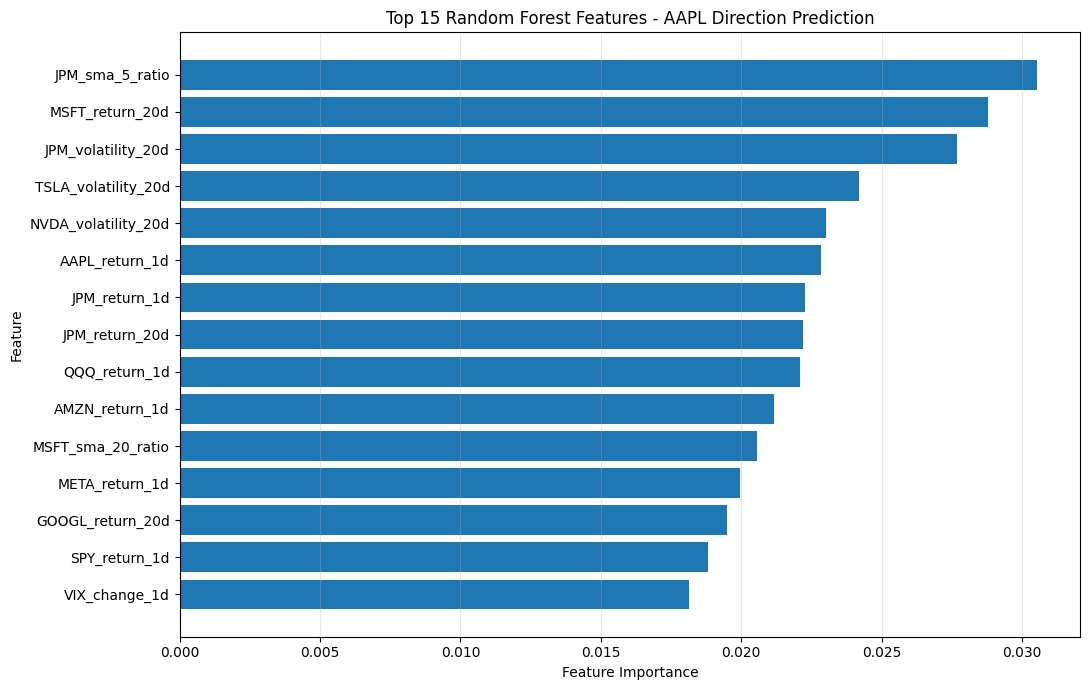

In [68]:
# ============================================================
# VISUALISE RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Select the 15 most important features
top_features = rf_feature_importance.head(15).copy()

# Reverse the order so the most important feature appears at the top
top_features = top_features.sort_values(
    by="Importance",
    ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

# Add chart labels and title
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Top 15 Random Forest Features - AAPL Direction Prediction"
)

# Improve chart readability
plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

# Display the chart
plt.show()

In [69]:
# ============================================================
# SAVE RANDOM FOREST EXPERIMENT RESULTS
# ============================================================

# Save all 25 walk-forward evaluations
rf_experiment_results_df.to_csv(
    os.path.join(
        results_path,
        "aapl_random_forest_walk_forward.csv"
    ),
    index=False
)

# Save average configuration performance
rf_summary.to_csv(
    os.path.join(
        results_path,
        "aapl_random_forest_configuration_comparison.csv"
    ),
    index=False
)

# Save baseline comparison
rf_baseline_comparison_df.to_csv(
    os.path.join(
        results_path,
        "aapl_random_forest_baseline_comparison.csv"
    ),
    index=False
)

# Save feature importance scores
rf_feature_importance.to_csv(
    os.path.join(
        results_path,
        "aapl_random_forest_feature_importance.csv"
    ),
    index=False
)

# Save the selected hyperparameters
pd.DataFrame([best_rf_config]).to_csv(
    os.path.join(
        results_path,
        "aapl_random_forest_best_parameters.csv"
    ),
    index=False
)

# Confirm saved files
print("RANDOM FOREST RESULTS SAVED SUCCESSFULLY")
print("=" * 60)

for filename in os.listdir(results_path):
    if filename.startswith("aapl_random_forest_"):
        print(filename)

RANDOM FOREST RESULTS SAVED SUCCESSFULLY
aapl_random_forest_walk_forward.csv
aapl_random_forest_configuration_comparison.csv
aapl_random_forest_baseline_comparison.csv
aapl_random_forest_feature_importance.csv
aapl_random_forest_best_parameters.csv


In [70]:
# ============================================================
# SAVE FINAL DEVELOPMENT RANDOM FOREST MODEL
# ============================================================

# Create the classification model folder
rf_model_path = os.path.join(
    PROJECT_PATH,
    "models",
    "classification"
)

os.makedirs(
    rf_model_path,
    exist_ok=True
)

# Create Random Forest using the selected configuration
final_rf_model = RandomForestClassifier(
    **best_rf_config,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using all development observations
final_rf_model.fit(
    X_development,
    y_development_aapl
)

# Define the model save location
rf_save_path = os.path.join(
    rf_model_path,
    "aapl_random_forest.pkl"
)

# Save the trained model
joblib.dump(
    final_rf_model,
    rf_save_path
)

# Confirm successful saving
print("RANDOM FOREST MODEL SAVED SUCCESSFULLY")
print("=" * 55)

print("Model location:")
print(rf_save_path)

print("\nTraining observations:", len(X_development))
print("Number of features:", X_development.shape[1])

RANDOM FOREST MODEL SAVED SUCCESSFULLY
Model location:
/content/drive/MyDrive/AI_Stock_Prediction/models/classification/aapl_random_forest.pkl

Training observations: 2510
Number of features: 63


In [71]:
# ============================================================
# FINAL RANDOM FOREST TEST EVALUATION
# ============================================================

# Generate predictions on the untouched test dataset
rf_test_predictions = final_rf_model.predict(X_test)

# Generate probabilities of an UP movement
rf_test_probabilities = final_rf_model.predict_proba(
    X_test
)[:, 1]

# Extract actual AAPL test targets
y_test_aapl = y_test["AAPL_direction"]

# Calculate classification metrics
rf_test_accuracy = accuracy_score(
    y_test_aapl,
    rf_test_predictions
)

rf_test_precision = precision_score(
    y_test_aapl,
    rf_test_predictions,
    zero_division=0
)

rf_test_recall = recall_score(
    y_test_aapl,
    rf_test_predictions,
    zero_division=0
)

rf_test_f1 = f1_score(
    y_test_aapl,
    rf_test_predictions,
    zero_division=0
)

rf_test_roc_auc = roc_auc_score(
    y_test_aapl,
    rf_test_probabilities
)

# Calculate baseline accuracy using development majority class
development_majority_class = y_development_aapl.mode()[0]

baseline_test_predictions = np.full(
    len(y_test_aapl),
    development_majority_class
)

baseline_test_accuracy = accuracy_score(
    y_test_aapl,
    baseline_test_predictions
)

# Display final test results
print("RANDOM FOREST FINAL TEST RESULTS")
print("=" * 65)

print(f"Accuracy:  {rf_test_accuracy:.4f}")
print(f"Precision: {rf_test_precision:.4f}")
print(f"Recall:    {rf_test_recall:.4f}")
print(f"F1-score:  {rf_test_f1:.4f}")
print(f"ROC-AUC:   {rf_test_roc_auc:.4f}")

print("\nBASELINE COMPARISON")
print("=" * 65)

print(f"Baseline accuracy:      {baseline_test_accuracy:.4f}")
print(f"Random Forest accuracy: {rf_test_accuracy:.4f}")

print(
    f"Improvement: {(rf_test_accuracy - baseline_test_accuracy) * 100:.2f} percentage points"
)

# Display confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 65)

print(
    confusion_matrix(
        y_test_aapl,
        rf_test_predictions
    )
)

# Display detailed classification report
print("\nCLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_test_aapl,
        rf_test_predictions,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

RANDOM FOREST FINAL TEST RESULTS
Accuracy:  0.5068
Precision: 0.5433
Recall:    0.4768
F1-score:  0.5079
ROC-AUC:   0.5068

BASELINE COMPARISON
Baseline accuracy:      0.5338
Random Forest accuracy: 0.5068
Improvement: -2.70 percentage points

CONFUSION MATRIX
[[112  95]
 [124 113]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        DOWN       0.47      0.54      0.51       207
          UP       0.54      0.48      0.51       237

    accuracy                           0.51       444
   macro avg       0.51      0.51      0.51       444
weighted avg       0.51      0.51      0.51       444



In [72]:
# ============================================================
# COMPARE LOGISTIC REGRESSION AND RANDOM FOREST
# ON THE UNSEEN TEST DATASET
# ============================================================

# Load the previously saved Logistic Regression model
logistic_model = joblib.load(
    os.path.join(
        PROJECT_PATH,
        "models",
        "classification",
        "aapl_logistic_regression.pkl"
    )
)

# Load its fitted scaler
logistic_scaler = joblib.load(
    os.path.join(
        PROJECT_PATH,
        "models",
        "classification",
        "aapl_logistic_scaler.pkl"
    )
)

# Scale test features using the previously fitted scaler
X_test_scaled = logistic_scaler.transform(X_test)

# Generate Logistic Regression predictions
logistic_test_predictions = logistic_model.predict(
    X_test_scaled
)

# Generate Random Forest predictions already trained on raw features
rf_test_predictions = final_rf_model.predict(X_test)

# Calculate Logistic Regression metrics
logistic_test_accuracy = accuracy_score(
    y_test_aapl,
    logistic_test_predictions
)

logistic_test_precision = precision_score(
    y_test_aapl,
    logistic_test_predictions,
    zero_division=0
)

logistic_test_recall = recall_score(
    y_test_aapl,
    logistic_test_predictions,
    zero_division=0
)

logistic_test_f1 = f1_score(
    y_test_aapl,
    logistic_test_predictions,
    zero_division=0
)

logistic_test_roc_auc = roc_auc_score(
    y_test_aapl,
    logistic_model.predict_proba(X_test_scaled)[:, 1]
)

# Create a comparison table
model_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        logistic_test_accuracy,
        logistic_test_precision,
        logistic_test_recall,
        logistic_test_f1,
        logistic_test_roc_auc
    ],
    "Random Forest": [
        rf_test_accuracy,
        rf_test_precision,
        rf_test_recall,
        rf_test_f1,
        rf_test_roc_auc
    ]
})

# Display comparison
print("FINAL MODEL COMPARISON ON UNSEEN TEST DATA")
print("=" * 75)

print(model_comparison.round(4).to_string(index=False))

# Display baseline performance
print("\nMAJORITY-CLASS BASELINE ACCURACY:")
print(f"{baseline_test_accuracy:.4f}")

FINAL MODEL COMPARISON ON UNSEEN TEST DATA
   Metric  Logistic Regression  Random Forest
 Accuracy               0.5090         0.5068
Precision               0.5364         0.5433
   Recall               0.5907         0.4768
 F1-score               0.5622         0.5079
  ROC-AUC               0.4885         0.5068

MAJORITY-CLASS BASELINE ACCURACY:
0.5338


In [73]:
# ============================================================
# INSTALL XGBOOST
# ============================================================

# Install the XGBoost machine learning library
!pip install xgboost -q

# Confirm installation
print("XGBoost installation completed successfully!")

XGBoost installation completed successfully!


In [74]:
# ============================================================
# IMPORT XGBOOST CLASSIFIER
# ============================================================

from xgboost import XGBClassifier

print("XGBoost classifier imported successfully!")

XGBoost classifier imported successfully!


In [75]:
# ============================================================
# XGBOOST WALK-FORWARD EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define a starting XGBoost configuration
xgb_params = {
    "n_estimators": 300,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1
}

xgb_fold_results = []

# Evaluate using the existing chronological folds
for fold, (train_idx, val_idx) in enumerate(
    rf_tscv.split(X_development), start=1
):

    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development_aapl.iloc[train_idx]
    y_fold_val = y_development_aapl.iloc[val_idx]

    # Calculate class balance using training data only
    negative_count = (y_fold_train == 0).sum()
    positive_count = (y_fold_train == 1).sum()

    fold_params = xgb_params.copy()
    fold_params["scale_pos_weight"] = (
        negative_count / positive_count
    )

    # Train the model
    xgb_model = XGBClassifier(**fold_params)
    xgb_model.fit(X_fold_train, y_fold_train)

    # Generate predictions
    y_pred = xgb_model.predict(X_fold_val)
    y_prob = xgb_model.predict_proba(X_fold_val)[:, 1]

    # Calculate evaluation metrics
    xgb_fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_fold_val, y_pred),
        "Precision": precision_score(
            y_fold_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_fold_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_fold_val, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_fold_val, y_prob)
    })

# Display fold-by-fold results
xgb_walk_forward_results = pd.DataFrame(xgb_fold_results)

print("XGBoost Walk-Forward Results:")
display(xgb_walk_forward_results)

print("\nAverage Performance Across Five Folds:")
display(
    xgb_walk_forward_results.drop(columns="Fold").mean().to_frame(
        name="Average Score"
    )
)

XGBoost Walk-Forward Results:


,Fold,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,0.552,0.581560,0.607407,0.594203,0.561610
1,2,0.408,0.427481,0.434109,0.430769,0.407585
2,3,0.512,0.506579,0.620968,0.557971,0.520865
3,4,0.508,0.557692,0.429630,0.485356,0.526506
4,5,0.500,0.549669,0.592857,0.570447,0.491429



Average Performance Across Five Folds:


,Average Score
Accuracy,0.496000
Precision,0.524596
Recall,0.536994
F1,0.527749
ROC_AUC,0.501599


In [76]:
# ============================================================
# SAVE XGBOOST WALK-FORWARD RESULTS
# ============================================================

# Save individual fold results
xgb_walk_forward_results.to_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "aapl_xgboost_walk_forward.csv"
    ),
    index=False
)

# Calculate and save average performance
xgb_average_results = (
    xgb_walk_forward_results
    .drop(columns="Fold")
    .mean()
    .to_frame(name="Average Score")
)

xgb_average_results.to_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "aapl_xgboost_average_results.csv"
    )
)

print("XGBoost evaluation results saved successfully!")

XGBoost evaluation results saved successfully!


In [77]:
# ============================================================
# XGBOOST HYPERPARAMETER EXPERIMENTS
# ============================================================

xgb_configurations = [
    {
        "n_estimators": 200,
        "max_depth": 2,
        "learning_rate": 0.03
    },
    {
        "n_estimators": 300,
        "max_depth": 2,
        "learning_rate": 0.05
    },
    {
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.05
    },
    {
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.02
    }
]

xgb_tuning_results = []

for config_number, config in enumerate(
    xgb_configurations, start=1
):

    fold_metrics = []

    for train_idx, val_idx in rf_tscv.split(X_development):

        X_fold_train = X_development.iloc[train_idx]
        X_fold_val = X_development.iloc[val_idx]

        y_fold_train = y_development_aapl.iloc[train_idx]
        y_fold_val = y_development_aapl.iloc[val_idx]

        negative_count = (y_fold_train == 0).sum()
        positive_count = (y_fold_train == 1).sum()

        model = XGBClassifier(
            **config,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            scale_pos_weight=negative_count / positive_count,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)
        probabilities = model.predict_proba(X_fold_val)[:, 1]

        fold_metrics.append({
            "Accuracy": accuracy_score(y_fold_val, predictions),
            "Precision": precision_score(
                y_fold_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_fold_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_fold_val, predictions, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                y_fold_val, probabilities
            )
        })

    average_metrics = pd.DataFrame(fold_metrics).mean()

    xgb_tuning_results.append({
        "Configuration": config_number,
        **config,
        **average_metrics.to_dict()
    })

xgb_tuning_results = pd.DataFrame(xgb_tuning_results)

print("XGBoost Configuration Comparison:")
display(
    xgb_tuning_results.sort_values(
        by="ROC_AUC", ascending=False
    ).reset_index(drop=True)
)

XGBoost Configuration Comparison:


,Configuration,n_estimators,max_depth,learning_rate,Accuracy,Precision,Recall,F1,ROC_AUC
0,2,300,2,0.05,0.5000,0.528338,0.533764,0.528959,0.504031
1,4,500,3,0.02,0.5032,0.529478,0.534646,0.530663,0.503074
2,1,200,2,0.03,0.5024,0.529540,0.544249,0.534340,0.497986
3,3,300,3,0.05,0.4896,0.521491,0.520562,0.518432,0.495769


In [78]:
# ============================================================
# SAVE XGBOOST CONFIGURATION COMPARISON
# ============================================================

xgb_tuning_results.to_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "aapl_xgboost_configuration_comparison.csv"
    ),
    index=False
)

# Identify the best configuration by ROC-AUC
best_xgb_configuration = (
    xgb_tuning_results
    .sort_values("ROC_AUC", ascending=False)
    .iloc[0]
)

print("Best XGBoost Configuration:")
display(best_xgb_configuration.to_frame(name="Value"))

print("\nConfiguration comparison saved successfully!")

Best XGBoost Configuration:


,Value
Configuration,2.000000
n_estimators,300.000000
max_depth,2.000000
learning_rate,0.050000
Accuracy,0.500000
Precision,0.528338
Recall,0.533764
F1,0.528959
ROC_AUC,0.504031



Configuration comparison saved successfully!


In [79]:
# ============================================================
# TRAIN AND SAVE BEST XGBOOST MODEL
# ============================================================

best_xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    scale_pos_weight=(
        (y_development_aapl == 0).sum()
        / (y_development_aapl == 1).sum()
    ),
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train using all development data
best_xgb_model.fit(
    X_development,
    y_development_aapl
)

# Save the trained model
xgb_model_path = os.path.join(
    PROJECT_PATH,
    "models",
    "classification",
    "aapl_xgboost.pkl"
)

joblib.dump(best_xgb_model, xgb_model_path)

print("Best XGBoost model trained and saved successfully!")
print("Model path:", xgb_model_path)

Best XGBoost model trained and saved successfully!
Model path: /content/drive/MyDrive/AI_Stock_Prediction/models/classification/aapl_xgboost.pkl


In [80]:
# ============================================================
# FINAL XGBOOST TEST EVALUATION
# ============================================================

# Generate test predictions
xgb_test_predictions = best_xgb_model.predict(X_test)

xgb_test_probabilities = (
    best_xgb_model.predict_proba(X_test)[:, 1]
)

# Calculate evaluation metrics
xgb_test_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(
        y_test["AAPL_direction"],
        xgb_test_predictions
    ),
    "Precision": precision_score(
        y_test["AAPL_direction"],
        xgb_test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test["AAPL_direction"],
        xgb_test_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        y_test["AAPL_direction"],
        xgb_test_predictions,
        zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test["AAPL_direction"],
        xgb_test_probabilities
    )
}

print("XGBoost Final Test Results:")
display(pd.DataFrame([xgb_test_results]).set_index("Model"))

# Confusion matrix
xgb_confusion = confusion_matrix(
    y_test["AAPL_direction"],
    xgb_test_predictions
)

print("\nConfusion Matrix:")
print(xgb_confusion)

print("\nClassification Report:")
print(
    classification_report(
        y_test["AAPL_direction"],
        xgb_test_predictions,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)

XGBoost Final Test Results:


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
XGBoost,0.531532,0.572139,0.485232,0.525114,0.537598



Confusion Matrix:
[[121  86]
 [122 115]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.50      0.58      0.54       207
          UP       0.57      0.49      0.53       237

    accuracy                           0.53       444
   macro avg       0.54      0.53      0.53       444
weighted avg       0.54      0.53      0.53       444



In [81]:
# ============================================================
# SAVE XGBOOST FINAL TEST RESULTS
# ============================================================

xgb_final_results_df = pd.DataFrame([xgb_test_results])

xgb_final_results_df.to_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "aapl_xgboost_final_test_results.csv"
    ),
    index=False
)

print("XGBoost final test results saved successfully!")

XGBoost final test results saved successfully!


In [82]:
# ============================================================
# CONSOLIDATED CLASSIFICATION MODEL COMPARISON
# ============================================================

final_classification_results = pd.DataFrame([
    {
        "Model": "Majority Class Baseline",
        "Accuracy": 0.5338,
        "Precision": None,
        "Recall": None,
        "F1": None,
        "ROC_AUC": None
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.5090,
        "Precision": 0.5364,
        "Recall": 0.5907,
        "F1": 0.5622,
        "ROC_AUC": 0.4885
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.5068,
        "Precision": 0.5433,
        "Recall": 0.4768,
        "F1": 0.5079,
        "ROC_AUC": 0.5068
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.531532,
        "Precision": 0.572139,
        "Recall": 0.485232,
        "F1": 0.525114,
        "ROC_AUC": 0.537598
    }
])

# Save consolidated comparison
comparison_path = os.path.join(
    PROJECT_PATH,
    "results",
    "final_classification_model_comparison.csv"
)

final_classification_results.to_csv(
    comparison_path,
    index=False
)

print("Final Classification Model Comparison:")
display(final_classification_results)

print("\nComparison saved to:", comparison_path)

Final Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Majority Class Baseline,0.533800,NaN,NaN,NaN,NaN
1,Logistic Regression,0.509000,0.536400,0.590700,0.562200,0.488500
2,Random Forest,0.506800,0.543300,0.476800,0.507900,0.506800
3,XGBoost,0.531532,0.572139,0.485232,0.525114,0.537598



Comparison saved to: /content/drive/MyDrive/AI_Stock_Prediction/results/final_classification_model_comparison.csv
